In [ ]:
# Last Update: 7/3/2026 ; 10 : 39 pm
#Preproc new wavelength fixed · PY

In [2]:
# MULTIMODAL PREPROCESSING: EEG + fNIRS 
# Set the paths based on your system before running the code
# you can adjust which subjects to process at the bottom of this cell

import os
import numpy as np
import scipy.io as sio
from scipy.io import loadmat
from scipy.signal import butter, filtfilt, resample
from scipy.interpolate import griddata
from scipy.interpolate import CloughTocher2DInterpolator  # NEW: used by the vectorized spatial_mapping()
from scipy.spatial import Delaunay  # NEW: used by the vectorized spatial_mapping()
import mne
import mne_icalabel
import pywt
import scipy.stats as stats
import pandas as pd
from scipy.interpolate import UnivariateSpline
import matplotlib.pyplot as plt  # NEW: needed for before/after preprocessing plots
import time
import datetime
import warnings
warnings.filterwarnings('ignore')

# CONFIGURATION
# BASE_DATASET_PATH = r"D:\Research\EEG-fNIRS\project\project\Dataset"
# OUTPUT_PATH = r"D:\Research\EEG-fNIRS\project\project\Results\MULTIMODAL_PREPROCESSED"
# FIX (path update per user's actual folder layout): the user's dataset is laid out as
# DATA\VP001-EEG, DATA\VP001-NIRS, ... (i.e. WITHOUT an intermediate numeric subfolder like
# DATA\001\VP001-EEG that the original code assumed). Paths below updated accordingly; see the
# matching fix in load_and_preprocess_fnirs() and process_subject() further down where
# subject_path/subject_num are removed for the same reason.
BASE_DATASET_PATH = r"E:\kntu\Thesis\codes\DATA"  # NEW: matches user's actual dataset folder
OUTPUT_PATH = r"E:\kntu\Thesis\codes\Results\MULTIMODAL_PREPROCESSED"  # NEW: matches user's actual output folder

# window parameters
EEG_WINDOW_LEN = 3.0      
EEG_STEP = 1.0            # 66% overlap
EEG_EPOCH_TMIN = 0.0
# EEG_EPOCH_TMAX = 8.0
# FIX (Problem 2): the n-back task period is 40 s long (2 s instruction + 40 s task + 20 s rest,
# Shin et al. 2018). The previous value of 8 s only let the sliding window traverse the first
# 8 s of each trial, discarding ~80% of the task period and, more importantly, was being applied
# on top of STIMULUS-level markers (every ~2 s) rather than TRIAL-level markers, which produced
# massive window overlap across different stimuli instead of covering the full cognitive-load trial.
EEG_EPOCH_TMAX = 40.0      # NEW: cover the full 40 s task period of a single n-back trial

FNIRS_WINDOW_LEN = 10.0  
FNIRS_STEP = 1.0          # 90% overlap
FNIRS_EPOCH_TMIN = 0.0
FNIRS_EPOCH_TMAX = 18.0   # bacause of the hemodynamic delay
# NOTE: FNIRS_EPOCH_TMAX is no longer used directly to bound the slide range (the EEG trial length
# now governs how many windows are produced, see extract_synchronized_windows below), but it is left
# untouched here exactly as before so no other part of the code/structure changes.

SFREQ_EEG = 200.0
SFREQ_FNIRS = 10.0      

# NEW (Problem 1 fix support): explicit trial-level marker maps based on the official dataset
# documentation (Shin et al. 2018, Dataset_description_MATLAB.pdf):
#   EEG  mrk_nback.event.desc : 112 = 0-back session, 128 = 2-back session, 144 = 3-back session
#   fNIRS mrk_nback.event.desc:   7 = 0-back session,   8 = 2-back session,   9 = 3-back session
# These TRIAL-onset codes (one per ~40 s task period) replace the old STIMULUS-level codes
# (16/48/64/80/96 for EEG; 1/2/3/4/5 placeholders) that fired every ~2 s within a trial.
EEG_TRIAL_LABEL_MAP = {112: 0, 128: 1, 144: 2}      # NEW: EEG session/trial-onset codes -> class
FNIRS_TRIAL_LABEL_MAP = {7: 0, 8: 1, 9: 2}          # NEW: fNIRS session/trial-onset codes -> class


# LOAD EEG DATA
def load_eeg_data(eeg_folder):
    cnt_path = os.path.join(eeg_folder, 'cnt_nback.mat')
    mrk_path = os.path.join(eeg_folder, 'mrk_nback.mat')
    
    print(f"Loading EEG from: {cnt_path}")
    
    # Load signal
    mat_cnt = sio.loadmat(cnt_path, struct_as_record=False, squeeze_me=True)
    real_cnt_keys = [k for k in mat_cnt.keys() if not k.startswith('__')]
    cnt_key = real_cnt_keys[0]
    cnt_struct = mat_cnt[cnt_key]
    
    data = cnt_struct.x.T
    sfreq = float(cnt_struct.fs)
    ch_names = [str(ch).strip() for ch in cnt_struct.clab]
    
    if np.max(np.abs(data)) > 1.0:
        data = data * 1e-6
    
    # making sure the sampling rate of 200
    if sfreq != SFREQ_EEG:
        print(f"Resampling from {sfreq} to {SFREQ_EEG} Hz")
        from scipy.signal import resample
        n_samples = int(data.shape[1] * SFREQ_EEG / sfreq)
        data = resample(data, n_samples, axis=1)
        sfreq = SFREQ_EEG
    
    info = mne.create_info(ch_names=ch_names, sfreq=sfreq, ch_types='eeg')
    raw = mne.io.RawArray(data, info, verbose=False)
    
    # EOG channels
    eog_channels = [ch for ch in ['VEOG', 'HEOG'] if ch in ch_names]
    if eog_channels:
        raw.set_channel_types({ch: 'eog' for ch in eog_channels})
    
    # NOTE: this generic standard_1005 template montage is kept ONLY for MNE-internal purposes that
    # need SOME position estimate for every channel (e.g. interpolate_bads()'s spherical-spline
    # interpolation in preprocess_eeg()). It is NOT used for the spatial_mapping() grid anymore --
    # get_eeg_mnt() (further below) uses the REAL, dataset-provided positions from mnt_nback.mat
    # (loaded at the end of this function) for that purpose instead.
    raw.set_montage('standard_1005', match_case=False, on_missing='ignore')
    
    # Load markers 
    mat_mrk = sio.loadmat(mrk_path, struct_as_record=False, squeeze_me=True)
    real_mrk_keys = [k for k in mat_mrk.keys() if not k.startswith('__')]
    mrk_key = real_mrk_keys[0]
    mrk_struct = mat_mrk[mrk_key]
    
    if hasattr(mrk_struct, 'time'):
        event_positions = np.round(mrk_struct.time * sfreq / 1000).astype(int)
    elif hasattr(mrk_struct, 'pos'):
        event_positions = np.array(mrk_struct.pos, dtype=int) - 1
    else:
        raise ValueError("Could not find 'time' or 'pos' in marker struct")
    
    # Event extraction
    if hasattr(mrk_struct, 'event') and hasattr(mrk_struct.event, 'desc'):
        desc = mrk_struct.event.desc
        if desc.ndim > 1:
            desc = desc.squeeze()
        event_codes = np.asarray(desc, dtype=int).flatten()
    elif hasattr(mrk_struct, 'y'):
        y = mrk_struct.y
        if y.ndim > 1:
            if y.shape[0] == 1 or y.shape[1] == 1:
                event_codes = y.flatten()
            else:
                event_codes = np.argmax(y, axis=0) + 1
        else:
            event_codes = y.flatten()
    else:
        event_codes = event_positions.copy()
    
    events = np.zeros((len(event_positions), 3), dtype=int)
    events[:, 0] = event_positions
    events[:, 2] = event_codes
    
    print(f"EEG loaded: {raw.n_times} samples, {sfreq} Hz, {len(events)} markers")
    print(f"unique markers: {np.unique(event_codes)}")

    # NEW: load the EEG mnt_nback.mat file -- REAL electrode 3D positions from this dataset,
    # confirmed via user-provided inspection script output: same struct format as the fNIRS
    # mnt_nback.mat already used in load_and_preprocess_fnirs (fields ['x','y','pos_3d','clab'],
    # pos_3d shape (3, 30), clab shape (30,)). This CORRECTS an earlier (wrong) assumption that EEG
    # had no equivalent .mat position file and had to fall back on MNE's generic standard_1005
    # template positions (raw.set_montage() below, which is KEPT unchanged -- it is still needed
    # for interpolate_bads()'s spherical-spline interpolation, an unrelated MNE-internal use). For
    # the azimuthal-equidistant spatial_mapping() grid, get_eeg_mnt() (defined further below) now
    # uses THIS real, dataset-provided mnt_nback.mat instead, exactly mirroring how fNIRS's own
    # mnt_nback.mat is already used for its spatial grid.
    mnt_path = os.path.join(eeg_folder, 'mnt_nback.mat')  # NEW
    mat_eeg_mnt = sio.loadmat(mnt_path, struct_as_record=False, squeeze_me=True)  # NEW
    real_eeg_mnt_keys = [k for k in mat_eeg_mnt.keys() if not k.startswith('__')]  # NEW
    eeg_mnt_struct = mat_eeg_mnt[real_eeg_mnt_keys[0]]  # NEW: has .pos_3d (3,30) and .clab (30,)
    print(f"EEG mnt_nback.mat loaded: pos_3d shape {np.asarray(eeg_mnt_struct.pos_3d).shape}")  # NEW

    # return raw, events, sfreq
    return raw, events, sfreq, eeg_mnt_struct  # CHANGED: also return the real electrode-position struct


# LOAD AND PREPROCESS FNIRS DATA
def load_and_preprocess_fnirs(subject_id):
    # subject_num = subject_id[2:]
    # subject_path = os.path.join(BASE_DATASET_PATH, subject_num)
    # fnirs_folder = os.path.join(subject_path, f"{subject_id}-NIRS")
    # FIX: removed the intermediate numeric subfolder (e.g. "001") which the user's actual dataset
    # layout does not have; fNIRS data sits directly under BASE_DATASET_PATH\VPxxx-NIRS.
    fnirs_folder = os.path.join(BASE_DATASET_PATH, f"{subject_id}-NIRS")  # NEW: flat folder structure
    
    cnt_path = os.path.join(fnirs_folder, 'cnt_nback.mat')
    mrk_path = os.path.join(fnirs_folder, 'mrk_nback.mat')  # NEW: fNIRS trial markers needed for the quality-check plot and (optionally) downstream use
    mnt_path = os.path.join(fnirs_folder, 'mnt_nback.mat')
    
    if not os.path.exists(cnt_path):
        raise FileNotFoundError(f"fNIRS file not found: {cnt_path}")
    
    print(f"Loading raw fNIRS from: {cnt_path}")
    
    # cnt_data = loadmat(cnt_path)
    # cnt = cnt_data['cnt_nback'][0, 0]
    #
    # mnt_data = loadmat(mnt_path)
    # mnt = mnt_data['mnt_nback'][0, 0]
    # FIX (Problem 1): the lines above used the default scipy.io.loadmat() call (struct_as_record=True),
    # while the rest of the pipeline (load_eeg_data) consistently uses
    # struct_as_record=False, squeeze_me=True. Mixing the two access styles is fragile: under the
    # default mode, struct fields are accessed via numpy structured-array indexing (e.g. cnt['oxy'][0,0]['x']),
    # while under struct_as_record=False they are accessed as plain Python attributes (e.g. cnt.oxy.x).
    # Verified against the actual VP001 .mat structure (inspect_data.py output): cnt_nback has fields
    # ['oxy','deoxy'], each of which is itself a struct with field 'x' holding the (n_samples, 36) signal,
    # and mnt_nback has fields ['x','y','pos_3d','clab'] holding (36,) coordinate vectors. Using the
    # unified squeeze_me=True / struct_as_record=False loader removes the [0,0] nested-indexing style and
    # avoids a silent shape mismatch in spatial_mapping() if the indexing assumption is ever wrong.
    mat_cnt = sio.loadmat(cnt_path, struct_as_record=False, squeeze_me=True)  # NEW: unified loader (matches load_eeg_data)
    real_cnt_keys = [k for k in mat_cnt.keys() if not k.startswith('__')]     # NEW
    cnt = mat_cnt[real_cnt_keys[0]]                                          # NEW: cnt is now a MATLAB-struct object with .oxy / .deoxy attributes

    mat_mnt = sio.loadmat(mnt_path, struct_as_record=False, squeeze_me=True)  # NEW: unified loader (matches load_eeg_data)
    real_mnt_keys = [k for k in mat_mnt.keys() if not k.startswith('__')]     # NEW
    mnt = mat_mnt[real_mnt_keys[0]]                                          # NEW: mnt is now a MATLAB-struct object with .x / .y attributes

    # Load fNIRS trial markers (NEW: needed only for the before/after QC plot at the end of this
    # function; segmentation itself happens later using EEG_TRIAL_LABEL_MAP / FNIRS_TRIAL_LABEL_MAP
    # inside extract_synchronized_windows, which keeps this function's return signature unchanged).
    fnirs_events_time = None  # NEW
    fnirs_events_code = None  # NEW
    if os.path.exists(mrk_path):  # NEW
        mat_fmrk = sio.loadmat(mrk_path, struct_as_record=False, squeeze_me=True)  # NEW
        real_fmrk_keys = [k for k in mat_fmrk.keys() if not k.startswith('__')]    # NEW
        fmrk = mat_fmrk[real_fmrk_keys[0]]                                         # NEW
        if hasattr(fmrk, 'time') and hasattr(fmrk, 'event') and hasattr(fmrk.event, 'desc'):  # NEW
            fnirs_events_time = np.asarray(fmrk.time).flatten()                     # NEW
            fnirs_events_code = np.asarray(fmrk.event.desc).flatten()               # NEW
    
    # Extract actual sampling rate (making sure it's 10Hz)
    # sfreq_fnirs_raw = float(cnt['fs'][0, 0]) if 'fs' in cnt.dtype.names else 10.0
    # FIX (Problem 1, continued): 'fs' is a field of cnt.oxy / cnt.deoxy (each a sub-struct), not of
    # cnt itself (verified: cnt_nback.oxy.fs == 10, cnt_nback.deoxy.fs == 10 in the inspected VP001 file).
    # The original line would raise an AttributeError under the new loader (cnt has no .dtype/.fs), so
    # it must read fs from the oxy sub-struct.
    sfreq_fnirs_raw = float(cnt.oxy.fs) if hasattr(cnt, 'oxy') and hasattr(cnt.oxy, 'fs') else 10.0  # NEW
    print(f"raw fNIRS sampling rate: {sfreq_fnirs_raw} Hz")
    
    # Extract raw oxy/deoxy
    # if 'oxy' in cnt.dtype.names:
    #     oxy_raw = cnt['oxy'][0, 0]['x']
    #     deoxy_raw = cnt['deoxy'][0, 0]['x']
    # else:
    #     oxy_raw = cnt['oxy']
    #     deoxy_raw = cnt['deoxy']
    # FIX (Problem 1, continued): with struct_as_record=False, squeeze_me=True, the signal matrix is
    # accessed as cnt.oxy.x / cnt.deoxy.x (plain attribute access), matching the (n_samples, 36) shape
    # confirmed in inspect_data.py for VP001 (21178, 36).
    oxy_raw = np.asarray(cnt.oxy.x, dtype=np.float64)     # NEW
    deoxy_raw = np.asarray(cnt.deoxy.x, dtype=np.float64)  # NEW
    
    print(f"Raw fNIRS: oxy {oxy_raw.shape}, deoxy {deoxy_raw.shape}")
    
    # Convert to HbO/HbR
    print("Converting to HbO/HbR...")
    hbo_raw, hbr_raw = calculate_hbo_hbr(oxy_raw, deoxy_raw)
    
    # Wavelet denoising 
    print("Wavelet denoising...")
    hbo_wv = wavelet_denoising(hbo_raw)
    hbr_wv = wavelet_denoising(hbr_raw)
    
    # MARA on full signal
    print("MARA...")
    hbo_mara = apply_mara(hbo_wv, fs=sfreq_fnirs_raw)
    hbr_mara = apply_mara(hbr_wv, fs=sfreq_fnirs_raw)
    
    # Low-pass filter 
    # print("ow-pass filter (0.15 Hz)...")
    # hbo_filtered = lowpass_filter(hbo_mara, fs=sfreq_fnirs_raw, cutoff=0.15)
    # hbr_filtered = lowpass_filter(hbr_mara, fs=sfreq_fnirs_raw, cutoff=0.15)
    # FIX (Problem 4): 0.15 Hz was an unjustified, overly conservative cutoff with no clear basis in
    # the EEG-fNIRS cognitive-workload literature reviewed for this thesis (Saadati et al. 2020 used
    # 0.08 Hz; Bunterngchit et al. 2024 used 0.2 Hz; both target removal of cardiac (~1 Hz) and
    # respiratory (~0.2-0.3 Hz) physiological noise while preserving the slow hemodynamic response to
    # cognitive load). Aligning the cutoff to 0.2 Hz brings the pipeline in line with the closest
    # published precedent on this exact dataset (Bunterngchit et al., IEEE JTEHM 2024) while still
    # removing high-frequency physiological noise.
    FNIRS_LOWPASS_CUTOFF_HZ = 0.2  # NEW: justified cutoff matching Bunterngchit et al. (2024) on the same dataset
    print(f"Low-pass filter ({FNIRS_LOWPASS_CUTOFF_HZ} Hz)...")  # NEW
    hbo_filtered = lowpass_filter(hbo_mara, fs=sfreq_fnirs_raw, cutoff=FNIRS_LOWPASS_CUTOFF_HZ)  # NEW
    hbr_filtered = lowpass_filter(hbr_mara, fs=sfreq_fnirs_raw, cutoff=FNIRS_LOWPASS_CUTOFF_HZ)  # NEW
    
    # dynamic downsampling to 10 Hz
    print(f"Resampling from {sfreq_fnirs_raw} Hz to {SFREQ_FNIRS} Hz...")
    from scipy.signal import resample
    n_samples = int(hbo_filtered.shape[0] * SFREQ_FNIRS / sfreq_fnirs_raw)
    hbo_resampled = resample(hbo_filtered, n_samples, axis=0)
    hbr_resampled = resample(hbr_filtered, n_samples, axis=0)
    
    # spatial mapping to 16x16
    print("Spatial mapping to 16x16...")
    hbo_mapped = spatial_mapping(hbo_resampled, mnt)
    hbr_mapped = spatial_mapping(hbr_resampled, mnt)
    
    # Stack as channels: (n_samples, 16, 16, 2)
    fnirs_data = np.stack([hbo_mapped, hbr_mapped], axis=-1)
    
    print(f"fNIRS preprocessed: {fnirs_data.shape}")

    # NEW (user request): save a before/after preprocessing QC plot for fNIRS (one representative
    # channel, raw HbO vs fully preprocessed/resampled HbO). Saved per-subject next to that subject's
    # output folder. Does not alter any returned value or downstream logic.
    try:  # NEW
        qc_channel = 0  # NEW: first fNIRS channel, arbitrary but fixed for reproducibility
        t_raw = np.arange(oxy_raw.shape[0]) / sfreq_fnirs_raw  # NEW
        t_proc = np.arange(hbo_resampled.shape[0]) / SFREQ_FNIRS  # NEW
        fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=False)  # NEW
        axes[0].plot(t_raw, oxy_raw[:, qc_channel], color='tab:red', linewidth=0.6)  # NEW
        axes[0].set_title(f"{subject_id} - fNIRS RAW HbO (channel {qc_channel}, before preprocessing)")  # NEW
        axes[0].set_xlabel("Time (s)")  # NEW
        axes[0].set_ylabel("HbO (raw units)")  # NEW
        axes[1].plot(t_proc, hbo_resampled[:, qc_channel], color='tab:blue', linewidth=0.8)  # NEW
        axes[1].set_title(f"{subject_id} - fNIRS PREPROCESSED HbO (channel {qc_channel}, after wavelet+MARA+lowpass+resample)")  # NEW
        axes[1].set_xlabel("Time (s)")  # NEW
        axes[1].set_ylabel("HbO (mmol/L)")  # NEW
        plt.tight_layout()  # NEW
        qc_dir = os.path.join(OUTPUT_PATH, subject_id)  # NEW
        os.makedirs(qc_dir, exist_ok=True)  # NEW
        fig.savefig(os.path.join(qc_dir, f"{subject_id}_fnirs_before_after.png"), dpi=150)  # NEW
        plt.close(fig)  # NEW
        print(f"Saved fNIRS before/after QC plot for {subject_id}")  # NEW
    except Exception as e:  # NEW
        print(f"Could not save fNIRS QC plot for {subject_id}: {e}")  # NEW
    
    return fnirs_data

# fNIRS HELPER FUNCTIONS
def calculate_hbo_hbr(oxy, deoxy):
    lambda1, lambda2 = 760, 850
    L = 3.0
    
    def get_dpf(lmbda, age=25):
        alpha, beta, gamma = 223.3, 0.05624, 0.8493
        delta, eps, zeta = -5.723e-7, 0.001245, -0.9025
        return alpha + beta * (age ** gamma) + delta * (lmbda ** 3) + eps * (lmbda ** 2) + zeta * lmbda
    
    dpf1 = get_dpf(lambda1)
    dpf2 = get_dpf(lambda2)
    
    e1_hbo, e1_hbr = 0.586, 1.54852
    e2_hbo, e2_hbr = 1.058, 0.69132
    
    denom = L * (e1_hbr * e2_hbo - e2_hbr * e1_hbo)
    hbo = (e1_hbr * (deoxy / dpf2) - e2_hbr * (oxy / dpf1)) / denom
    hbr = (e1_hbo * (oxy / dpf1) - e2_hbo * (deoxy / dpf2)) / denom
    
    return hbo, hbr

def wavelet_denoising(data, alpha=0.1, wavelet='db5'):
    cleaned = np.zeros_like(data)
    n_samples, n_channels = data.shape
    
    for ch in range(n_channels):
        signal = data[:, ch]
        level = min(int(np.floor(np.log2(n_samples))), 6)
        coeffs = pywt.wavedec(signal, wavelet, level=level)
        new_coeffs = [coeffs[0]]
        for i in range(1, len(coeffs)):
            d_coeffs = coeffs[i].copy()
            sigma = np.median(np.abs(d_coeffs - np.median(d_coeffs))) / 0.6745
            if sigma > 0:
                threshold = sigma * stats.norm.ppf(1 - alpha / 2)
                d_coeffs[np.abs(d_coeffs) > threshold] = 0
            new_coeffs.append(d_coeffs)
        cleaned[:, ch] = pywt.waverec(new_coeffs, wavelet)[:n_samples]
    
    return cleaned

def apply_mara(data, fs=10.0, window_size=41, threshold_factor=1.8):
    n_samples, n_channels = data.shape
    corrected = np.zeros_like(data)
    edge_len = int(0.5 * fs)
    
    for ch in range(n_channels):
        signal = data[:, ch].copy()
        msd = pd.Series(signal).rolling(window=window_size, center=True, min_periods=1).std().to_numpy()
        threshold = np.median(msd) + (threshold_factor * np.std(msd))
        ma_mask = (msd > threshold).astype(int)
        
        diff_mask = np.diff(ma_mask, prepend=0, append=0)
        starts = np.where(diff_mask == 1)[0]
        ends = np.where(diff_mask == -1)[0]
        indices = sorted(list(set([0, n_samples] + list(starts) + list(ends))))
        segments = [signal[indices[i]:indices[i+1]].copy() for i in range(len(indices) - 1)]
        
        if not segments:
            corrected[:, ch] = signal
            continue
        
        final_parts = [segments[0]]
        for i in range(1, len(segments)):
            prev_seg = final_parts[-1]
            curr_seg = segments[i]
            val_prev = np.median(prev_seg[-edge_len:]) if len(prev_seg) >= edge_len else prev_seg[-1]
            val_curr = np.median(curr_seg[:edge_len]) if len(curr_seg) >= edge_len else curr_seg[0]
            shift = val_prev - val_curr
            
            if ma_mask[indices[i]] == 1:
                x = np.arange(len(curr_seg))
                s_val = max(np.var(curr_seg) * len(curr_seg), 1e-6)
                try:
                    spline = UnivariateSpline(x, curr_seg, s=s_val)
                    curr_seg = curr_seg - spline(x)
                    val_curr_new = np.median(curr_seg[:edge_len]) if len(curr_seg) >= edge_len else curr_seg[0]
                    curr_seg += (val_prev - val_curr_new)
                except:
                    curr_seg += shift
            else:
                if abs(shift) > 2 * np.std(msd):
                    curr_seg += shift
            final_parts.append(curr_seg)
        
        full_signal = np.concatenate(final_parts)[:n_samples]
        t_idx = np.arange(n_samples)
        original_trend = np.polyval(np.polyfit(t_idx, data[:, ch], 1), t_idx)
        corrected_trend = np.polyval(np.polyfit(t_idx, full_signal, 1), t_idx)
        full_signal += (original_trend - corrected_trend)
        corrected[:, ch] = full_signal
    
    return corrected

def lowpass_filter(data, fs=10.0, cutoff=0.15):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(3, normal_cutoff, btype='low')
    filtered = np.zeros_like(data)
    for ch in range(data.shape[1]):
        filtered[:, ch] = filtfilt(b, a, data[:, ch])
    return filtered

def spatial_mapping(data, mnt):
    n_samples, n_channels = data.shape
    # x_coords = np.asarray(mnt.x).flatten()
    # y_coords = np.asarray(mnt.y).flatten()
    # FIX (projection accuracy): mnt.x / mnt.y are pre-computed 2D coordinates from the BBCI
    # toolbox's own projection, which is not necessarily the azimuthal equidistant projection
    # described in the TSFNet reference paper (Zhang, Yin, Yuan, Sensors 2025). Using the raw 3D
    # channel positions (mnt.pos_3d, shape (3, n_channels), confirmed present in the fNIRS mnt_nback
    # struct via inspect_data.py) and projecting them with a genuine azimuthal equidistant
    # projection (angular distance from the vertex is preserved: theta = angle from north pole,
    # phi = azimuthal angle) more faithfully reproduces the paper's methodology than reusing the
    # toolbox's built-in 2D coordinates.
    pos_3d = np.asarray(mnt.pos_3d, dtype=np.float64)  # NEW: shape (3, n_channels)
    x3d, y3d, z3d = pos_3d[0, :], pos_3d[1, :], pos_3d[2, :]  # NEW
    r = np.sqrt(x3d**2 + y3d**2 + z3d**2)  # NEW
    r_safe = np.where(r > 0, r, 1.0)  # NEW: avoid division by zero for any degenerate channel position
    theta = np.arccos(np.clip(z3d / r_safe, -1.0, 1.0))  # NEW: angle from the vertex (pole)
    phi = np.arctan2(y3d, x3d)  # NEW: azimuthal angle
    x_coords = theta * np.cos(phi)  # NEW: azimuthal equidistant projection
    y_coords = theta * np.sin(phi)  # NEW
    
    grid_x, grid_y = np.mgrid[min(x_coords):max(x_coords):16j, 
                               min(y_coords):max(y_coords):16j]
    points = np.column_stack((x_coords, y_coords))
    
    # mapped = np.zeros((n_samples, 16, 16), dtype=np.float32)
    # for t in range(n_samples):
    #     grid_z = griddata(points, data[t, :], (grid_x, grid_y), method='cubic', fill_value=0)
    #     mapped[t] = grid_z
    # PERF FIX: the loop above calls griddata() once per time sample, re-computing the Delaunay
    # triangulation of `points` from scratch every single time -- even though `points` (electrode
    # positions) NEVER changes across time samples for a given subject; only the values (data[t,:])
    # change. Confirmed via VP001/VP002 real runs, EEG spatial mapping (394930 / 395238 samples at
    # 200 Hz) was the dominant cost of the ~28-32 min per-subject runtime. griddata's 'cubic' 2D
    # path internally builds scipy.interpolate.CloughTocher2DInterpolator(points, values, ...),
    # which officially supports (a) being given a pre-built scipy.spatial.Delaunay triangulation
    # instead of raw points, and (b) vector-valued `values` of shape (n_points, ...trailing_dims),
    # interpolating all trailing "columns" (here: all time samples) in one batched call. Verified
    # numerically bit-identical (max abs diff = 0.0) against the old per-sample loop on synthetic
    # data of the same shape before applying this change (see chat history for the verification
    # script). This is a pure performance refactor -- the interpolation math is unchanged.
    tri = Delaunay(points)  # NEW: triangulation depends only on `points`, computed ONCE instead of n_samples times
    values = data.T  # NEW: (n_samples, n_channels) -> (n_channels, n_samples); CloughTocher2DInterpolator
                      # NEW: requires values.shape[0] == points.shape[0] (== n_channels here)
    interp = CloughTocher2DInterpolator(tri, values, fill_value=0)  # NEW: gradient estimation + patch setup done once, for all time samples together
    result = interp((grid_x, grid_y))  # NEW: shape (16, 16, n_samples) -- one batched evaluation instead of n_samples separate ones
    mapped = np.transpose(result, (2, 0, 1)).astype(np.float32)  # NEW: (16, 16, n_samples) -> (n_samples, 16, 16), matching the original return shape/dtype exactly
    
    return mapped

# NEW (EEG spatial mapping support): spatial_mapping() above was written for fNIRS, which reads
# 3D channel positions from mnt.pos_3d (a field already present in the dataset's mnt_nback.mat
# struct). EEG has no equivalent .mat mnt struct -- its electrode positions instead live inside
# the MNE montage set in load_eeg_data() via raw.set_montage('standard_1005', match_case=False,
# on_missing='ignore'). _EEGMontageAdapter + get_eeg_mnt() below extract those positions, in the
# SAME channel order as raw.ch_names (so they line up 1:1 with data columns passed to
# spatial_mapping), into a lightweight object exposing .pos_3d with shape (3, n_channels) --
# exactly the interface spatial_mapping() already expects -- so spatial_mapping() itself does not
# need to change at all and is reused UNCHANGED for EEG, with the same azimuthal equidistant
# projection methodology already used for fNIRS.
# NEW (EEG spatial mapping support): spatial_mapping() above was written for fNIRS, which reads
# 3D channel positions from mnt.pos_3d (a field present in the dataset's fNIRS mnt_nback.mat
# struct). The EEG folder has its OWN mnt_nback.mat with the exact same format (pos_3d shape
# (3, 30), clab shape (30,)), confirmed via direct inspection of VP001-EEG/mnt_nback.mat -- so EEG
# positions come from the REAL, dataset-provided file, not from MNE's generic standard_1005
# template (an earlier, incorrect assumption; see the comment above raw.set_montage() in
# load_eeg_data(), where that template montage is kept only for interpolate_bads()'s internal use).
# _EEGMontageAdapter + get_eeg_mnt() below select, from the full 30-channel mnt_nback.mat struct,
# only the positions of the channels that SURVIVED preprocessing (raw.ch_names, after
# VEOG/HEOG/TP9 are dropped in preprocess_eeg), matched BY NAME against mnt_nback.mat's own clab
# list (channel order in cnt_nback.mat and mnt_nback.mat is not guaranteed to be identical, so
# matching by name rather than by raw positional index is required for correctness). The result is
# a lightweight object exposing .pos_3d with shape (3, n_channels) -- exactly the interface
# spatial_mapping() already expects -- so spatial_mapping() itself needs no changes at all.
class _EEGMontageAdapter:  # NEW
    """Minimal stand-in for the fNIRS .mat mnt struct, exposing only the .pos_3d attribute that
    spatial_mapping() reads."""
    def __init__(self, pos_3d):  # NEW
        self.pos_3d = pos_3d  # NEW: shape (3, n_channels), matching mnt.pos_3d's shape for fNIRS

def get_eeg_mnt(raw, eeg_mnt_struct):  # CHANGED: now takes the real mnt_nback.mat struct (loaded once in load_eeg_data) instead of deriving positions from raw's MNE montage
    """
    Builds an _EEGMontageAdapter (pos_3d shape (3, n_channels)) from the REAL electrode 3D
    positions in the dataset's own EEG mnt_nback.mat (eeg_mnt_struct.pos_3d / .clab), selecting
    and ordering them to match raw.ch_names exactly. Must be called AFTER any channel drops
    (VEOG/HEOG/TP9 in preprocess_eeg) so the returned position order matches the channel order of
    the data that will be passed to spatial_mapping().
    """
    full_clab = [str(c).strip() for c in np.asarray(eeg_mnt_struct.clab).flatten()]  # NEW: e.g. 30 names, same cleanup style as cnt_struct.clab in load_eeg_data
    full_pos_3d = np.asarray(eeg_mnt_struct.pos_3d, dtype=np.float64)  # NEW: shape (3, 30)
    name_to_idx = {name: i for i, name in enumerate(full_clab)}  # NEW
    name_to_idx_upper = {name.upper(): i for i, name in enumerate(full_clab)}  # NEW: case-insensitive fallback, matches match_case=False used elsewhere in this pipeline

    pos_list = []  # NEW
    missing = []  # NEW
    for ch in raw.ch_names:  # NEW
        idx = name_to_idx.get(ch, name_to_idx_upper.get(ch.upper(), None))  # NEW
        if idx is None:  # NEW: channel present in raw but not found in mnt_nback.mat's clab list
            missing.append(ch)  # NEW
            pos_list.append([0.0, 0.0, 0.0])  # NEW: origin fallback (theta=0 -> maps to grid center)
        else:  # NEW
            pos_list.append(full_pos_3d[:, idx])  # NEW

    if missing:  # NEW
        print(f"  WARNING: {len(missing)} EEG channel(s) not found in mnt_nback.mat's clab "  # NEW
              f"(spatial_mapping will place them at the grid center): {missing}")  # NEW

    pos_3d = np.array(pos_list, dtype=np.float64).T  # NEW: shape (3, n_channels)
    return _EEGMontageAdapter(pos_3d)  # NEW

# PREPROCESS EEG
def preprocess_eeg(raw, events):
    print("Preprocessing EEG...")

    # NEW (user request): keep a copy of the raw signal (one representative channel) for the
    # before/after preprocessing QC plot saved at the end of this function.
    raw_before_qc = raw.copy()  # NEW
    
    raw_filtered = raw.copy().notch_filter(freqs=50.0, picks='eeg', verbose=False)
    raw_filtered.filter(l_freq=1.0, h_freq=40.0, method='fir', verbose=False)
    
    # Detect bad channels
    raw_temp = raw_filtered.copy().filter(l_freq=10.0, h_freq=40.0, method='fir', verbose=False)
    eeg_picks = mne.pick_types(raw_temp.info, eeg=True, eog=False)
    eeg_names = [raw_temp.ch_names[idx] for idx in eeg_picks]
    
    temp_data = raw_temp.get_data(picks=eeg_picks)
    stds = np.std(temp_data, axis=1)
    median_std = np.median(stds)
    mad = np.median(np.abs(stds - median_std)) if np.median(np.abs(stds - median_std)) > 0 else 1e-6
    corr_matrix = np.corrcoef(temp_data)
    mean_corrs = np.mean(corr_matrix, axis=1)
    
    bad_channels = []
    for i, ch_name in enumerate(eeg_names):
        if ch_name.upper() in ['VEOG', 'HEOG', 'TP9']:
            continue
        if stds[i] > (median_std + 4.5 * mad) or stds[i] < (median_std - 4.5 * mad) or mean_corrs[i] < 0.30:
            bad_channels.append(ch_name)
    
    if bad_channels:
        print(f"Bad channels: {bad_channels}")
        raw_filtered.info['bads'] = bad_channels
    
    # NEW (fix support): remember which channels were flagged as bad BEFORE interpolate_bads()
    # resets info['bads']. This list is needed further below to correctly compute the ICA rank,
    # since interpolate_bads(reset_bads=True) clears info['bads'] and the original code's
    # exclude='bads' filter therefore silently included the interpolated channels in the ICA fit.
    interpolated_channels = list(raw_filtered.info['bads'])  # NEW
    
    if raw_filtered.info['bads']:
        raw_filtered.interpolate_bads(reset_bads=True, verbose=False)
    
    raw_filtered.set_eeg_reference('average', projection=False, verbose=False)
    
    # ICA
    picks_for_ica = mne.pick_types(raw_filtered.info, eeg=True, eog=False, exclude='bads')
    # corrected_rank = max(1, len(picks_for_ica) - 1)
    # FIX (rank problem): interpolate_bads(reset_bads=True) above already cleared info['bads'],
    # so exclude='bads' here has NOTHING to exclude and picks_for_ica silently includes every
    # interpolated channel. Interpolated channels are linear combinations of their neighbours and
    # add NO new degrees of freedom to the data, so the true data rank is
    # (n_good_channels - 1 for CAR - n_interpolated_channels), not just (n_channels - 1).
    # Asking ICA (via n_components=corrected_rank) for more components than the true rank forces
    # the algorithm to spread a single real source (e.g. the eye-blink dipole) across multiple
    # weak, "diluted" components, none of which individually scores high enough in ICLabel
    # (whether by argmax or by the probability threshold added above) to be flagged as
    # 'eye blink'. This is very likely the main reason eye-blink artifacts survive in this
    # pipeline's output while code 1 (which never interpolates channels) does not have this issue.

###########

    # corrected_rank = max(1, len(picks_for_ica) - 1 - len(interpolated_channels))
    # print(f"ICA rank: {corrected_rank} (picks={len(picks_for_ica)}, interpolated={len(interpolated_channels)})")
    # ica = mne.preprocessing.ICA(n_components=corrected_rank, method='infomax',
    #                             fit_params=dict(extended=True), random_state=42, verbose=False)
    # FIX (rank problem, cleaner solution): the manual rank correction above (subtracting the number
    # of interpolated channels) is a reasonable workaround, but n_components=0.99 solves the same
    # problem more robustly and automatically: instead of a FIXED component count, ICA's internal PCA
    # step keeps only as many components as needed to explain 99% of the data's variance. Interpolated
    # channels contribute (near-)zero additional variance since they are linear combinations of their
    # neighbours, so PCA naturally discards that redundant dimensionality without needing to manually
    # count and subtract interpolated channels. This avoids asking ICA for more components than the
    # true data rank, which is what caused the eye-blink source to be diluted across several weak,
    # under-scored components in the original pipeline (see comment above find_bads_eog for the full
    # rationale of that issue).
    # method='picard' (Ablin, Cardoso & Gramfort, 2018, IEEE Signal Processing Letters) is mathematically
    # equivalent to extended infomax but converges faster and more reliably; it is the ICA algorithm
    # used in the reference implementation (code 1) and is increasingly the default recommendation in
    # recent BCI/EEG preprocessing literature.
    print(f"ICA: using variance-based component selection (99% explained variance), "  # NEW
          f"picks={len(picks_for_ica)}, interpolated={len(interpolated_channels)}")     # NEW
    ica = mne.preprocessing.ICA(n_components=0.99, method='picard',                     # NEW
                                fit_params=dict(ortho=False, extended=True),            # NEW
                                random_state=42, verbose=False)                          # NEW
    ica.fit(raw_filtered, picks=picks_for_ica)


#########    

####
    ic_labels = mne_icalabel.label_components(raw_filtered, ica, method='iclabel')

    ARTIFACT_CLASSES_IDX = {  # NEW: standard ICLabel class order (verified from ica.labels_scores_ shape=(n,7))
        'brain': 0, 'muscle artifact': 1, 'eye blink': 2,
        'heart beat': 3, 'line noise': 4, 'channel noise': 5, 'other': 6
    }
    ARTIFACT_TARGETS = ['eye blink', 'eye movement', 'muscle artifact', 'line noise']  # NEW
    PROB_THRESHOLD = 0.30  # NEW

    # Original argmax-based selection (unchanged logic)
    artifact_idx_argmax = [idx for idx, label in enumerate(ic_labels['labels'])
                           if label in ARTIFACT_TARGETS]  # CHANGED: renamed

    # NEW: probability-threshold based selection using ica.labels_scores_ (shape: n_components x 7)
    artifact_idx_prob = []  # NEW
    proba_matrix = ica.labels_scores_  # NEW: verified shape (27, 7) for this dataset
    for comp_idx in range(proba_matrix.shape[0]):  # NEW
        for cls_name in ARTIFACT_TARGETS:  # NEW
            cls_col = ARTIFACT_CLASSES_IDX.get(cls_name)  # NEW
            if cls_col is not None and proba_matrix[comp_idx, cls_col] >= PROB_THRESHOLD:  # NEW
                artifact_idx_prob.append(comp_idx)  # NEW
                break  # NEW: one match per component is enough

    # eog_indices, eog_scores = None, None  (did not exist in the previous version of this file)
    # FIX (Problem: no direct EOG-correlation check): code 1 (the reference implementation) relies
    # primarily on mne.preprocessing.ICA.find_bads_eog(), which correlates each ICA component's time
    # course directly against the RECORDED VEOG channel -- a ground-truth signal, independent of
    # ICLabel's scalp-topography/spectrum-based classifier. Code 2 previously relied ONLY on
    # ICLabel (via argmax and/or probability threshold), which never consults the VEOG/HEOG channels
    # that are already loaded and typed as 'eog' in load_eeg_data(). Adding find_bads_eog() here
    # gives ICA exclusion a second, independent detection path so that a genuine eye-blink component
    # that ICLabel under-scores (e.g. due to the rank/dilution issue fixed above) can still be
    # caught via its correlation with the real VEOG signal, matching code 1's methodology.
    eog_indices_veog, eog_scores_veog = [], None  # NEW: defaults in case VEOG channel is missing
    eog_indices_heog, eog_scores_heog = [], None  # NEW: defaults in case HEOG channel is missing
    try:  # NEW
        if 'VEOG' in raw.ch_names:  # NEW: raw is the ORIGINAL (unfiltered) signal passed into this function, matching code 1's use of raw_input
            eog_indices_veog, eog_scores_veog = ica.find_bads_eog(raw, ch_name='VEOG', threshold=2.0, verbose=False)  # NEW
            print(f"  find_bads_eog(VEOG) flagged components: {eog_indices_veog}")  # NEW
        if 'HEOG' in raw.ch_names:  # NEW: also check HEOG (horizontal eye movements), which code 1 did not check but is available in this dataset
            eog_indices_heog, eog_scores_heog = ica.find_bads_eog(raw, ch_name='HEOG', threshold=2.0, verbose=False)  # NEW
            print(f"  find_bads_eog(HEOG) flagged components: {eog_indices_heog}")  # NEW
    except Exception as e:  # NEW
        print(f"  find_bads_eog failed: {e}")  # NEW
#########

    
    # NEW (methodological decision, not a named standard algorithm -- see justification below):
    # Gate EOG-correlation-only hits (components flagged ONLY via find_bads_eog, with no ICLabel
    # support) behind an ICLabel 'brain' probability ceiling. Rationale: EOG-correlation is a
    # well-established artifact-detection method (Jung et al. 1998/2000; implemented in EEGLAB,
    # FieldTrip, MNE), and combining multiple independent artifact detectors is itself a recognized
    # practice (e.g. SASICA, Chaumon et al. 2015, J. Neurosci. Methods, which combines EOG-correlation,
    # autocorrelation, topography focus, and discontinuity as independent criteria). However, the
    # literature also documents that EOG-correlation alone can produce false positives, since some
    # genuine brain sources (e.g. frontal activity related to eye-movement planning / corollary
    # discharge) can correlate with EOG without being ocular artifacts themselves. The specific
    # threshold below (BRAIN_PROB_CEILING = 0.5) is NOT a published/validated cutoff from any single
    # paper -- it is a conservative engineering choice made for this thesis to reduce the risk of
    # discarding real brain signal when a component's only supporting evidence is EOG-correlation.
    # Any component that ALSO has independent ICLabel support (argmax or probability threshold) is
    # NOT affected by this gate and is still excluded regardless of its 'brain' probability.
    BRAIN_PROB_CEILING = 0.5  # NEW: conservative, thesis-specific choice -- not a literature-standard value
    BRAIN_CLASS_COL = ARTIFACT_CLASSES_IDX['brain']  # NEW
    
    eog_only_idx = (set(eog_indices_veog) | set(eog_indices_heog)) - (set(artifact_idx_argmax) | set(artifact_idx_prob))  # NEW: components flagged ONLY by EOG-correlation, with no ICLabel support at all
    eog_only_rescued = {idx for idx in eog_only_idx if proba_matrix[idx, BRAIN_CLASS_COL] >= BRAIN_PROB_CEILING}  # NEW: rescue if ICLabel itself thinks it's likely brain signal
    if eog_only_rescued:  # NEW
        print(f"  Rescued from EOG-only rejection (ICLabel brain-prob >= {BRAIN_PROB_CEILING}): {sorted(eog_only_rescued)}")  # NEW
    
    artifact_idx = sorted(
        (set(artifact_idx_argmax) | set(artifact_idx_prob) | set(eog_indices_veog) | set(eog_indices_heog))
        - eog_only_rescued
    )  # CHANGED: same union as before, minus the conservative brain-probability rescue applied only to EOG-only hits


    
###########
    # NEW: detailed log for each flagged component
    all_class_names = ['brain', 'muscle artifact', 'eye blink', 'heart beat', 'line noise', 'channel noise', 'other']  # NEW
    for comp_idx in artifact_idx:  # NEW
        probs_str = ", ".join([f"{all_class_names[c]}={proba_matrix[comp_idx, c]:.2f}"  # NEW
                               for c in range(7)])  # NEW
        reason = []  # NEW
        if comp_idx in artifact_idx_argmax:  # NEW
            reason.append(f"argmax='{ic_labels['labels'][comp_idx]}'")  # NEW
        if comp_idx in artifact_idx_prob:  # NEW
            reason.append(f"prob>={PROB_THRESHOLD}")  # NEW
        if comp_idx in eog_indices_veog:  # NEW
            reason.append("VEOG-correlation")  # NEW
        if comp_idx in eog_indices_heog:  # NEW
            reason.append("HEOG-correlation")  # NEW
        print(f"  IC{comp_idx} flagged [{', '.join(reason)}]: {probs_str}")  # NEW

    ica.exclude = artifact_idx
    if len(ica.exclude) > 0:
        ica.apply(raw_filtered, verbose=False)
        print(f"Removed {len(ica.exclude)} ICA components")
    else:
        print("Removed 0 ICA components (no artifact ICs detected)")  # NEW
    

####
        
    
    # Case-insensitive channel drop
    channels_to_drop = [ch for ch in raw_filtered.ch_names if ch.upper() in ['VEOG', 'HEOG', 'TP9']]
    if channels_to_drop:
        raw_filtered.drop_channels(channels_to_drop)
        print(f"Dropped channels: {channels_to_drop}")

    # NEW (user request, updated): save before/after preprocessing QC plots for EEG showing ALL
    # channels at once (not just one representative channel). Two SEPARATE figures are produced:
    # one figure with all RAW channels stacked, one figure with all PREPROCESSED channels stacked.
    # Each channel is plotted on its own horizontal row using a fixed vertical offset (the standard
    # "butterfly/stacked montage" view used by EEG viewers such as MNE's raw.plot()), so all channels
    # remain visually separable in a single image instead of being overlaid on top of each other.
    try:  # NEW
        def _plot_all_channels_stacked(raw_obj, title, color, tmin=None, tmax=None):  # CHANGED: added tmin/tmax for zoomed view
            sfreq_plot = raw_obj.info['sfreq']               # NEW
            if tmin is not None or tmax is not None:         # NEW: optional time-window crop
                start_sample = int((tmin or 0.0) * sfreq_plot)             # NEW
                stop_sample = int((tmax * sfreq_plot)) if tmax is not None else None  # NEW
                data = raw_obj.get_data(start=start_sample, stop=stop_sample)         # NEW
                t = (np.arange(data.shape[1]) + start_sample) / sfreq_plot            # NEW
            else:                                            # NEW
                data = raw_obj.get_data()                      # NEW: (n_channels, n_times)
                t = np.arange(data.shape[1]) / sfreq_plot        # NEW
            ch_names_plot = raw_obj.ch_names                # NEW

            # Use the robust (median absolute deviation based) per-channel spread to set a fixed
            # vertical offset between channels, so that channels with very different amplitudes
            # (e.g. after CAR/ICA vs raw) are still readable and non-overlapping within the same figure.
            #spread = np.median(np.abs(data - np.median(data, axis=1, keepdims=True))) * 8 + 1e-12  # NEW
            spread = np.median(np.abs(data - np.median(data, axis=1, keepdims=True))) * 30 + 1e-12  # NEW
            n_ch_plot = data.shape[0]                        # NEW
            #fig_h = max(6, 0.28 * n_ch_plot)  # NEW: scale figure height with channel count
            fig_h = max(6, 0.5 * n_ch_plot)                 # NEW: scale figure height with channel count
            fig, ax = plt.subplots(figsize=(14, fig_h))      # NEW
            for i in range(n_ch_plot):                       # NEW
                offset = (n_ch_plot - 1 - i) * spread         # NEW: top channel = first channel name
                ax.plot(t, data[i] + offset, color=color, linewidth=0.4)  # NEW
            ax.set_yticks([(n_ch_plot - 1 - i) * spread for i in range(n_ch_plot)])  # NEW
            ax.set_yticklabels(ch_names_plot, fontsize=6)    # NEW
            ax.set_xlabel("Time (s)")                        # NEW
            ax.set_ylabel("Channel")                         # NEW
            ax.set_title(title)                              # NEW
            plt.tight_layout()                                # NEW
            return fig                                        # NEW

        fig_before = _plot_all_channels_stacked(  # NEW
            raw_before_qc, "EEG RAW - All Channels (before preprocessing)", 'tab:red'  # NEW
        )  # NEW
        fig_after = _plot_all_channels_stacked(  # NEW
            raw_filtered, "EEG PREPROCESSED - All Channels (after notch+bandpass+CAR+ICA)", 'tab:blue'  # NEW
        )  # NEW
        fig_before_zoom = _plot_all_channels_stacked(  # NEW: zoomed 10-30s view
            raw_before_qc, "EEG RAW - All Channels (before preprocessing, 10-30s)", 'tab:red', tmin=10.0, tmax=30.0  # NEW
        )  # NEW
        fig_after_zoom = _plot_all_channels_stacked(  # NEW: zoomed 10-30s view
            raw_filtered, "EEG PREPROCESSED - All Channels (after notch+bandpass+CAR+ICA, 10-30s)", 'tab:blue', tmin=10.0, tmax=30.0  # NEW
        )  # NEW
        

        # The subject_id is not directly available inside this function (it only receives raw/events),
        # so the figures are saved using generic names inside OUTPUT_PATH/_tmp_eeg_qc and renamed by
        # the caller (process_subject) right after this function returns. This keeps this function's
        # signature and call sites unchanged.
        tmp_qc_dir = os.path.join(OUTPUT_PATH, "_tmp_eeg_qc")  # NEW
        os.makedirs(tmp_qc_dir, exist_ok=True)  # NEW
        fig_before.savefig(os.path.join(tmp_qc_dir, "last_eeg_before_allchannels.png"), dpi=150)  # NEW
        fig_after.savefig(os.path.join(tmp_qc_dir, "last_eeg_after_allchannels.png"), dpi=150)  # NEW
        fig_before_zoom.savefig(os.path.join(tmp_qc_dir, "last_eeg_before_allchannels_zoom10_30.png"), dpi=150)  # NEW
        fig_after_zoom.savefig(os.path.join(tmp_qc_dir, "last_eeg_after_allchannels_zoom10_30.png"), dpi=150)  # NEW
        plt.close(fig_before)  # NEW
        plt.close(fig_after)  # NEW
        plt.close(fig_before_zoom)  # NEW
        plt.close(fig_after_zoom)  # NEW
    except Exception as e:  # NEW
        print(f"Could not save EEG QC plot: {e}")  # NEW
    
    return raw_filtered


# SYNCHRONIZED SLIDING WINDOW EXTRACTION 
# def extract_synchronized_windows(eeg_raw, fnirs_data, events, sfreq_eeg):
# CHANGED: added eeg_spatial_data parameter -- the pre-computed, spatially-mapped (16x16 grid)
# continuous EEG signal for this subject (shape (n_times, 16, 16), produced once in
# process_subject() via spatial_mapping(), mirroring how fNIRS is spatially mapped once before
# windowing rather than per-window). eeg_raw (the MNE Raw object, channel x time) is still passed
# in and still used, but now ONLY for the amplitude-based artifact rejection check below, since
# that threshold (120 uV) is calibrated in electrode voltage units and is not a meaningful check
# on interpolated grid values.
def extract_synchronized_windows(eeg_raw, eeg_spatial_data, fnirs_data, events, sfreq_eeg):  # CHANGED

    print("Extracting synchronized asymmetric sliding windows...")
    print(f"EEG window: {EEG_WINDOW_LEN}s, step: {EEG_STEP}s")
    print(f"fNIRS window: {FNIRS_WINDOW_LEN}s, step: {FNIRS_STEP}s")
    
    # support both marker formats 
    # label_map = {
    #     1: 0, 2: 1, 3: 1, 4: 2, 5: 2,
    #     16: 0, 48: 1, 64: 1, 80: 2, 96: 2
    # }
    #
    # valid_codes = [1, 2, 3, 4, 5, 16, 48, 64, 80, 96]
    # target_events = events[np.isin(events[:, 2], valid_codes)]
    # FIX (Problem 2): the codes above (1-5, 16/48/64/80/96) are STIMULUS-level markers that fire
    # roughly every 2 s within a 40 s trial (per Shin et al. 2018 / Dataset_description_MATLAB.pdf,
    # codes 16/48/64/80/96 correspond to individual target/non-target number presentations, not to
    # the start of a cognitive-load trial). Sliding a window from each of these stimulus markers
    # caused massive, redundant overlap between windows anchored to different stimuli within the same
    # trial, rather than a clean traversal of the full 40 s task period for that trial. The correct
    # trial-onset codes, confirmed directly from the VP001 .mat structure (inspect_data.py output:
    # mrk_nback.event.desc contains 144 etc., and the dataset documentation confirms 112/128/144 =
    # 0-/2-/3-back SESSION start), are used instead: each trial-onset marker anchors exactly one
    # 40 s task period, which is then traversed by the (unchanged) sliding-window loop below.
    label_map = EEG_TRIAL_LABEL_MAP  # NEW: trial-onset codes (112/128/144) -> class label, defined at top of script
    valid_codes = list(EEG_TRIAL_LABEL_MAP.keys())  # NEW
    target_events = events[np.isin(events[:, 2], valid_codes)]  # NEW: now selects one event per ~40s trial instead of one event per ~2s stimulus
    
    print(f"found {len(target_events)} trial markers")
    if len(target_events) == 0:
        print(f"No trial markers found. Available markers: {np.unique(events[:, 2])}")
        return np.array([]), np.array([]), np.array([])
    
    window_samples_eeg = int(EEG_WINDOW_LEN * sfreq_eeg)
    window_samples_fnirs = int(FNIRS_WINDOW_LEN * SFREQ_FNIRS)
    
    max_slide_seconds = EEG_EPOCH_TMAX - EEG_WINDOW_LEN
    step_seconds = EEG_STEP
    
    eeg_windows = []
    fnirs_windows = []
    labels = []
    
    for ev in target_events:
        event_sample_eeg = ev[0]
        raw_code = ev[2]
        
        label = label_map.get(raw_code, -1)
        if label == -1:
            continue
        
        event_time = event_sample_eeg / sfreq_eeg
        
        for offset_sec in np.arange(0.0, max_slide_seconds + 0.001, step_seconds):
            
            # EEG window
            w_start_eeg = int(event_sample_eeg + np.round(offset_sec * sfreq_eeg))
            w_end_eeg = w_start_eeg + window_samples_eeg
            
            # fNIRS window 
            w_start_fnirs = int(np.round((event_time + offset_sec) * SFREQ_FNIRS))
            w_end_fnirs = w_start_fnirs + window_samples_fnirs
            
            if w_end_eeg > eeg_raw.n_times:
                continue
            
            if w_end_fnirs > fnirs_data.shape[0]:
                continue
            
            # Extract EEG
            # eeg_slice = eeg_raw.get_data(start=w_start_eeg, stop=w_end_eeg)
            # if np.max(np.abs(eeg_slice)) > 120e-6:
            #     continue
            # CHANGED (EEG spatial mapping): the SAVED EEG window must now be the spatially-mapped
            # (16, 16, 600) grid representation, not the raw (28, 600) channel-space slice. The
            # artifact-rejection amplitude check, however, stays on the raw channel-space slice
            # (eeg_slice_raw) since the 120 uV threshold is only meaningful in electrode voltage
            # units, not on cubic-interpolated grid values.
            eeg_slice_raw = eeg_raw.get_data(start=w_start_eeg, stop=w_end_eeg)  # CHANGED: renamed, QC-only now
            if np.max(np.abs(eeg_slice_raw)) > 120e-6:  # CHANGED: uses eeg_slice_raw
                continue

            # NEW: slice the pre-computed spatially-mapped EEG (n_times, 16, 16) at the SAME sample
            # range as eeg_slice_raw (both index the same continuous recording at sfreq_eeg=200Hz),
            # then transpose (600, 16, 16) -> (16, 16, 600) i.e. grid-H x grid-W x time, per spec.
            eeg_slice_spatial = eeg_spatial_data[w_start_eeg:w_end_eeg]  # NEW: (600, 16, 16)
            eeg_slice = eeg_slice_spatial.transpose(1, 2, 0)             # NEW: (16, 16, 600) -- this is what gets saved

            # Extract fNIRS
            fnirs_slice = fnirs_data[w_start_fnirs:w_end_fnirs]
            fnirs_slice = fnirs_slice.transpose(3, 0, 1, 2) 
            
            eeg_windows.append(eeg_slice)
            fnirs_windows.append(fnirs_slice)
            labels.append(label)
    
    eeg_windows = np.array(eeg_windows)
    fnirs_windows = np.array(fnirs_windows)
    labels = np.array(labels)
    
    print(f"Extracted {len(labels)} synchronized windows")
    if len(labels) > 0:
        print(f"Label distribution: {np.bincount(labels)}")
    
    return eeg_windows, fnirs_windows, labels



LOG_FILE = os.path.join(OUTPUT_PATH, "processing_log.txt")  # NEW: log file path

def log_message(msg):  # NEW: helper to print + append to log file
    timestamp = datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    line = f"[{timestamp}] {msg}"
    print(line)
    os.makedirs(OUTPUT_PATH, exist_ok=True)
    with open(LOG_FILE, "a", encoding="utf-8") as f:
        f.write(line + "\n")



# MAIN PROCESSING FUNCTION
def process_subject(subject_id):
    t0 = time.time()  # NEW
    log_message(f"START processing {subject_id}")  # NEW
    print(f"Processing {subject_id}")
    
    # subject_num = subject_id[2:]
    # subject_path = os.path.join(BASE_DATASET_PATH, subject_num)
    # eeg_folder = os.path.join(subject_path, f"{subject_id}-EEG")
    # FIX: same flat-folder-structure fix as in load_and_preprocess_fnirs() above; EEG data sits
    # directly under BASE_DATASET_PATH\VPxxx-EEG, with no intermediate numeric subfolder.
    eeg_folder = os.path.join(BASE_DATASET_PATH, f"{subject_id}-EEG")  # NEW: flat folder structure
    
    if not os.path.exists(eeg_folder):
        log_message(f"SKIPPED {subject_id}: EEG folder not found")  # NEW
        print(f"EEG folder not found: {eeg_folder}")
        return
    
    try:
        print("\n Loading EEG...")
        # raw_eeg, events, sfreq_eeg = load_eeg_data(eeg_folder)
        raw_eeg, events, sfreq_eeg, eeg_mnt_struct = load_eeg_data(eeg_folder)  # CHANGED: also receive the real EEG mnt_nback.mat struct
        
        print("\n Loading and preprocessing fNIRS...")
        fnirs_data = load_and_preprocess_fnirs(subject_id)
        
        # NEW (bug fix): normalization must happen BEFORE window extraction, not after.
        # extract_synchronized_windows() below slices fnirs_windows directly out of fnirs_data,
        # so if fnirs_data is normalized AFTER that call, the windows already saved are un-normalized
        # and the later normalization line has no effect on the saved output (confirmed by
        # VP011's quality report: fNIRS std=0.000367 instead of ~1.0). Moving the normalization
        # here, right after fnirs_data is produced and before any windowing happens, fixes this.
        print("\n Normalizing fNIRS (subject-level, before windowing)...")  # NEW
        fnirs_data = (fnirs_data - fnirs_data.mean(axis=0, keepdims=True)) / (fnirs_data.std(axis=0, keepdims=True) + 1e-8)  # NEW: moved here from below
        
        print("\n Preprocessing EEG...")
        raw_eeg_clean = preprocess_eeg(raw_eeg, events)

        # NEW (EEG per-subject normalization fix support): compute per-channel mean/std from the
        # FULL cleaned, continuous EEG signal (after filtering/CAR/ICA) BEFORE any windowing happens.
        # FIX (per-window vs per-subject normalization): the previous EEG normalization (further
        # below, in the "Normalizing..." section) computed a separate z-score for EACH extracted
        # window independently (axis=-1 over the window's 600 time samples). With a window as short
        # as 3 s, this local z-scoring is noisy/unstable and, more importantly, completely erases any
        # systematic difference in absolute EEG amplitude/power between subjects or between cognitive
        # load levels within a subject -- the model can then only see the RELATIVE waveform shape
        # inside each isolated 3 s window, which is a much weaker and more subject-specific signal.
        # This is very likely a major contributor to the severe overfitting observed during model
        # training (train acc ~96% vs val/test acc near chance level): the model latches onto
        # subject-specific residual noise patterns within each locally-renormalized window instead of
        # learning generalizable cognitive-load-related features. Computing mean/std once per subject
        # over the full continuous recording (mirroring the fNIRS per-subject normalization fix above)
        # and applying those FIXED per-channel statistics to every window extracted from that subject
        # preserves the relative amplitude structure across windows and across load levels, which
        # should generalize better to unseen subjects.
        eeg_full_data = raw_eeg_clean.get_data()  # NEW: shape (n_channels, n_times), fully preprocessed continuous signal
        eeg_subject_mean = eeg_full_data.mean(axis=-1, keepdims=True)  # NEW: shape (n_channels, 1)
        eeg_subject_std = eeg_full_data.std(axis=-1, keepdims=True) + 1e-8  # NEW: shape (n_channels, 1)
        print(f"\n EEG per-subject normalization stats computed: "  # NEW
              f"mean range [{eeg_subject_mean.min():.2e}, {eeg_subject_mean.max():.2e}], "  # NEW
              f"std range [{eeg_subject_std.min():.2e}, {eeg_subject_std.max():.2e}]")  # NEW

        # NEW (EEG spatial mapping, TSFNet paper Sec. 2.3): project the EEG electrodes onto a 16x16
        # spatial grid via azimuthal equidistant projection, exactly as already done for fNIRS
        # (spatial_mapping() + mnt), instead of leaving EEG as raw (channel x time). This is applied
        # ONCE to the full continuous, already-cleaned recording (not per-window) for the same
        # efficiency reason fNIRS is spatially mapped once in load_and_preprocess_fnirs() before
        # windowing: with 66% window overlap, per-window mapping would re-run cubic griddata
        # interpolation on largely the same timepoints hundreds of times over.
        print("\n Spatial mapping EEG to 16x16...")  # NEW
        # eeg_mnt = get_eeg_mnt(raw_eeg_clean)  # electrode positions in raw_eeg_clean.ch_names order (post channel-drop)
        eeg_mnt = get_eeg_mnt(raw_eeg_clean, eeg_mnt_struct)  # CHANGED: uses REAL mnt_nback.mat positions, matched by clab name, not MNE's guessed standard_1005
        eeg_spatial_full = spatial_mapping(eeg_full_data.T, eeg_mnt)  # NEW: (n_channels,n_times).T -> (n_times, n_channels) in, (n_times, 16, 16) out
        print(f"EEG spatially mapped: {eeg_spatial_full.shape}")  # NEW

        # NEW: per-subject normalization of the spatially-mapped EEG, applied to the FULL continuous
        # grid signal before windowing -- mirrors exactly how fNIRS is normalized in this same
        # function (fnirs_data = (fnirs_data - mean)/std over axis=0, i.e. per grid-cell across
        # time). This supersedes the old per-channel normalization (eeg_subject_mean/eeg_subject_std
        # above), which no longer applies now that EEG windows are (16,16,600) grid data rather than
        # (28,600) channel data; eeg_subject_mean/eeg_subject_std are kept above only for the
        # informational print (channel-space signal scale), not used for normalization below anymore.
        eeg_spatial_full = (eeg_spatial_full - eeg_spatial_full.mean(axis=0, keepdims=True)) / (  # NEW
            eeg_spatial_full.std(axis=0, keepdims=True) + 1e-8)  # NEW

        # NEW (user request): finalize the EEG before/after QC plots (now two all-channel figures)
        # for this specific subject by renaming the temp files produced inside preprocess_eeg()
        # (which has no access to subject_id).
        try:  # NEW
            tmp_qc_before = os.path.join(OUTPUT_PATH, "_tmp_eeg_qc", "last_eeg_before_allchannels.png")  # NEW
            tmp_qc_after = os.path.join(OUTPUT_PATH, "_tmp_eeg_qc", "last_eeg_after_allchannels.png")    # NEW
            tmp_qc_before_zoom = os.path.join(OUTPUT_PATH, "_tmp_eeg_qc", "last_eeg_before_allchannels_zoom10_30.png")  # NEW
            tmp_qc_after_zoom = os.path.join(OUTPUT_PATH, "_tmp_eeg_qc", "last_eeg_after_allchannels_zoom10_30.png")    # NEW
            if os.path.exists(tmp_qc_before) and os.path.exists(tmp_qc_after):  # NEW
                final_qc_dir = os.path.join(OUTPUT_PATH, subject_id)  # NEW
                os.makedirs(final_qc_dir, exist_ok=True)  # NEW
                final_qc_before = os.path.join(final_qc_dir, f"{subject_id}_eeg_before_allchannels.png")  # NEW
                final_qc_after = os.path.join(final_qc_dir, f"{subject_id}_eeg_after_allchannels.png")    # NEW
                os.replace(tmp_qc_before, final_qc_before)  # NEW
                os.replace(tmp_qc_after, final_qc_after)    # NEW
                if os.path.exists(tmp_qc_before_zoom) and os.path.exists(tmp_qc_after_zoom):  # NEW
                    final_qc_before_zoom = os.path.join(final_qc_dir, f"{subject_id}_eeg_before_allchannels_zoom10_30.png")  # NEW
                    final_qc_after_zoom = os.path.join(final_qc_dir, f"{subject_id}_eeg_after_allchannels_zoom10_30.png")    # NEW
                    os.replace(tmp_qc_before_zoom, final_qc_before_zoom)  # NEW
                    os.replace(tmp_qc_after_zoom, final_qc_after_zoom)    # NEW
                print(f"Saved EEG before/after (all-channels) QC plots for {subject_id}")  # NEW
        except Exception as e:  # NEW
            print(f"Could not finalize EEG QC plot for {subject_id}: {e}")  # NEW
        
        print("\n Extracting synchronized asymmetric windows...")
        # eeg_windows, fnirs_windows, labels = extract_synchronized_windows(
        #     raw_eeg_clean, fnirs_data, events, sfreq_eeg
        # )
        # CHANGED: pass eeg_spatial_full (the pre-computed 16x16-grid-mapped continuous EEG) in
        # addition to raw_eeg_clean (still needed inside for the channel-space QC amplitude check).
        eeg_windows, fnirs_windows, labels = extract_synchronized_windows(  # CHANGED
            raw_eeg_clean, eeg_spatial_full, fnirs_data, events, sfreq_eeg  # CHANGED
        )
        
        if len(labels) == 0:
            log_message(f"WARNING {subject_id}: no windows extracted")  # NEW
            print(f"No windows extracted for {subject_id}")
            return
        
        print("\n Normalizing...")
        # EEG: (n_windows, n_channels, n_times) 
        # eeg_windows = (eeg_windows - eeg_windows.mean(axis=-1, keepdims=True)) / (eeg_windows.std(axis=-1, keepdims=True) + 1e-8)
        # FIX (per-window -> per-subject EEG normalization): the line above computed a fresh z-score
        # for every single window independently (per-window mean/std over its own 600 time samples).
        # As explained in the comment above where eeg_subject_mean/eeg_subject_std are computed, this
        # erases systematic amplitude differences between cognitive-load levels and between subjects,
        # which is very likely contributing to the poor generalization (near-chance val/test accuracy)
        # observed during model training. Applying the FIXED per-subject statistics computed once
        # from the full continuous recording (broadcast across all windows and all time samples via
        # reshape to (1, n_channels, 1)) fixes this while still correcting for each subject's overall
        # signal scale, mirroring the per-subject normalization already used for fNIRS.
        # eeg_mean_broadcast = eeg_subject_mean.reshape(1, -1, 1)  # (1, n_channels, 1) for broadcasting over (N, n_channels, n_times)
        # eeg_std_broadcast = eeg_subject_std.reshape(1, -1, 1)
        # eeg_windows = (eeg_windows - eeg_mean_broadcast) / eeg_std_broadcast
        # CHANGED (EEG spatial mapping): eeg_windows is now (n_windows, 16, 16, 600) grid data, not
        # (n_windows, 28, 600) channel data, so the per-channel normalization above no longer applies
        # and is removed. EEG normalization now happens EARLIER, on the full continuous spatially-
        # mapped signal (eeg_spatial_full) before windowing -- see the "NEW: per-subject
        # normalization of the spatially-mapped EEG" block above, right after spatial_mapping() is
        # called -- exactly mirroring how fNIRS is normalized in grid space before windowing. No
        # further EEG normalization is needed here; eeg_windows already carries normalized values.
        
        # fNIRS: (n_windows, 2, 100, 16, 16)
        # fnirs_windows = (fnirs_windows - fnirs_windows.mean(axis=2, keepdims=True)) / (fnirs_windows.std(axis=2, keepdims=True) + 1e-8)
        # FIX (Problem 3): ...
        # fnirs_data = (fnirs_data - fnirs_data.mean(axis=0, keepdims=True)) / (fnirs_data.std(axis=0, keepdims=True) + 1e-8)
        # BUG FIX (moved): this line was dead code -- fnirs_windows had already been sliced from the
        # un-normalized fnirs_data by extract_synchronized_windows() before this point ran. The actual
        # normalization now happens earlier, right after load_and_preprocess_fnirs() returns and
        # before extract_synchronized_windows() is called. See that block above.
        
        print("\n Saving...")
        sub_out_dir = os.path.join(OUTPUT_PATH, subject_id)
        os.makedirs(sub_out_dir, exist_ok=True)
        
        # np.save(os.path.join(sub_out_dir, f"{subject_id}_eeg_windows.npy"), eeg_windows)
        # np.save(os.path.join(sub_out_dir, f"{subject_id}_fnirs_windows.npy"), fnirs_windows)
        # np.save(os.path.join(sub_out_dir, f"{subject_id}_labels.npy"), labels)
        # NEW (user request): for the first verification run, only save outputs for the very first
        # subject so correctness can be checked before running the full 26-subject batch. The save
        # calls below are commented out for all subjects except VP001; uncomment the three np.save
        # lines below (and remove/relax this condition) once the pipeline has been verified.
#        #if subject_id == "VP001":  # NEW: save outputs only for the first subject during verification
        np.save(os.path.join(sub_out_dir, f"{subject_id}_eeg_windows.npy"), eeg_windows)    # NEW
        np.save(os.path.join(sub_out_dir, f"{subject_id}_fnirs_windows.npy"), fnirs_windows)  # NEW
        np.save(os.path.join(sub_out_dir, f"{subject_id}_labels.npy"), labels)               # NEW
        # else:                                                                                    # NEW
        #     # Saving suppressed for subjects other than VP001 during this verification run.        # NEW
        #     pass                                                                                  # NEW
        
        print(f"\n {subject_id} completed!")
        print(f"EEG windows: {eeg_windows.shape}")
        print(f"fNIRS windows: {fnirs_windows.shape}")
        print(f"Labels: {np.bincount(labels)}")
        elapsed = (time.time() - t0) / 60  # NEW
        log_message(f"DONE {subject_id} in {elapsed:.1f} min | EEG: {eeg_windows.shape} | fNIRS: {fnirs_windows.shape} | Labels: {np.bincount(labels)}")  # NEW
        
    except Exception as e:
        elapsed = (time.time() - t0) / 60  # NEW
        log_message(f"ERROR processing {subject_id} after {elapsed:.1f} min: {str(e)}")  # NEW
        print(f"Error processing {subject_id}: {str(e)}")
        import traceback
        traceback.print_exc()

# RUN
if __name__ == "__main__":
    total_t0 = time.time()  # NEW
    log_message("===== PIPELINE STARTED =====")  # NEW
    print("MULTIMODAL PREPROCESSING PIPELINE")
    print(f"EEG window: {EEG_WINDOW_LEN}s, step: {EEG_STEP}s")
    print(f"fNIRS window: {FNIRS_WINDOW_LEN}s, step: {FNIRS_STEP}s")
    print(f"fNIRS epoch: {FNIRS_EPOCH_TMAX}s")
    print(f"fNIRS sampling rate: {SFREQ_FNIRS} Hz")
    
    # for sub_num in range(1, 27):
    # NEW (verification run): limited to VP001 only, per user's request to first check correctness
    # on a single subject before running the full 26-subject batch. Change back to range(1, 27)
    # once the pipeline has been verified.
#    for sub_num in range(1, 2):  # NEW: VP001 only, for verification
    for sub_num in range(26, 27):  # NEW
        subject_id = f"VP{sub_num:03d}"
        process_subject(subject_id)

    
    print("ALL THE SELECTED SUBJECTS PROCESSED")

[2026-07-04 23:53:16] ===== PIPELINE STARTED =====
MULTIMODAL PREPROCESSING PIPELINE
EEG window: 3.0s, step: 1.0s
fNIRS window: 10.0s, step: 1.0s
fNIRS epoch: 18.0s
fNIRS sampling rate: 10.0 Hz
[2026-07-04 23:53:16] START processing VP026
Processing VP026

 Loading EEG...
Loading EEG from: E:\kntu\Thesis\codes\DATA\VP026-EEG\cnt_nback.mat
EEG loaded: 386760 samples, 200.0 Hz, 567 markers
unique markers: [ 16  48  64  80  96 112 128 144]
EEG mnt_nback.mat loaded: pos_3d shape (3, 30)

 Loading and preprocessing fNIRS...
Loading raw fNIRS from: E:\kntu\Thesis\codes\DATA\VP026-NIRS\cnt_nback.mat
raw fNIRS sampling rate: 10.0 Hz
Raw fNIRS: oxy (20656, 36), deoxy (20656, 36)
Converting to HbO/HbR...
Wavelet denoising...
MARA...
Low-pass filter (0.2 Hz)...
Resampling from 10.0 Hz to 10.0 Hz...
Spatial mapping to 16x16...
fNIRS preprocessed: (20656, 16, 16, 2)
Saved fNIRS before/after QC plot for VP026

 Normalizing fNIRS (subject-level, before windowing)...

 Preprocessing EEG...
Preprocessi

In [1]:
#Diagnostic check signal exists · PY
"""
چک تشخیصی: آیا داده‌ی نهایی (بعد از کل پیش‌پردازش) اصلاً سیگنال قابل‌تفکیک بین کلاس‌ها دارد؟
این مستقل از هر مدل یادگیری عمیقی است -- فقط آمار ساده روی خودِ فایل‌های .npy پیش‌پردازش‌شده.

اجرا روی یک یا چند سوژه از پوشه‌ی MULTIMODAL_PREPROCESSED.
"""
import numpy as np
from scipy import stats

subject = "VP002"  # یک سوژه با کیفیت خوب را انتخاب کنید (کانال bad کم، ICA کمتر حذف کرده)
base = rf"E:\kntu\Thesis\codes\Results\MULTIMODAL_PREPROCESSED\{subject}"

eeg = np.load(f"{base}\\{subject}_eeg_windows.npy")      # (N, 16, 16, 600)
nirs = np.load(f"{base}\\{subject}_fnirs_windows.npy")   # (N, 2, 100, 16, 16)
labels = np.load(f"{base}\\{subject}_labels.npy")        # (N,)

print(f"شکل EEG: {eeg.shape}, fNIRS: {nirs.shape}, لیبل‌ها: {np.bincount(labels)}")

# ===== چک ۱: آیا میانگین دامنه‌ی EEG (RMS در طول زمان) بین کلاس‌ها فرق دارد؟ =====
eeg_rms = np.sqrt(np.mean(eeg**2, axis=(1, 2, 3)))  # یک عدد به‌ازای هر پنجره
for cls in [0, 1, 2]:
    vals = eeg_rms[labels == cls]
    print(f"EEG RMS کلاس {cls}: میانگین={vals.mean():.4f}  std={vals.std():.4f}  n={len(vals)}")

f_stat, p_val = stats.f_oneway(eeg_rms[labels == 0], eeg_rms[labels == 1], eeg_rms[labels == 2])
print(f"ANOVA برای EEG RMS بین سه کلاس: F={f_stat:.3f}, p={p_val:.4f}")
print("(اگر p<0.05: حداقل یک سیگنال خام تفکیک‌پذیر بین کلاس‌ها وجود دارد)")

# ===== چک ۲: همین برای fNIRS (میانگین HbO در طول پنجره) =====
nirs_hbo_mean = nirs[:, 0, :, :, :].mean(axis=(1, 2, 3))  # میانگین HbO کل پنجره
for cls in [0, 1, 2]:
    vals = nirs_hbo_mean[labels == cls]
    print(f"fNIRS HbO mean کلاس {cls}: میانگین={vals.mean():.4f}  std={vals.std():.4f}")

f_stat2, p_val2 = stats.f_oneway(nirs_hbo_mean[labels == 0], nirs_hbo_mean[labels == 1], nirs_hbo_mean[labels == 2])
print(f"ANOVA برای fNIRS HbO mean بین سه کلاس: F={f_stat2:.3f}, p={p_val2:.4f}")

# ===== چک ۳: وجود NaN/Inf که ممکن است بی‌صدا مدل را خراب کرده باشد =====
print(f"\nNaN در EEG: {np.isnan(eeg).any()}   Inf در EEG: {np.isinf(eeg).any()}")
print(f"NaN در fNIRS: {np.isnan(nirs).any()}   Inf در fNIRS: {np.isinf(nirs).any()}")

# ===== چک ۴: خانه‌های "مرده" (همیشه صفر) در طول پنجره‌ها =====
eeg_std_per_cell = eeg.std(axis=(0, 3))  # std هر خانه (16,16) روی همه‌ی پنجره‌ها و زمان
dead_cells = (eeg_std_per_cell < 1e-6).sum()
print(f"\nخانه‌های مرده EEG: {dead_cells}/256 ({dead_cells/256*100:.1f}%)")

# ===== چک ۵: آیا ترتیب eeg/fnirs/labels واقعاً هم‌راستا مانده؟ =====
# با مقایسه‌ی طول هر سه آرایه و یک‌بار چک شکل، مطمئن می‌شویم هیچ‌کدام جدا از هم دستکاری نشده‌اند.
assert eeg.shape[0] == nirs.shape[0] == labels.shape[0], "طول EEG/fNIRS/labels با هم یکی نیست!"
print(f"\nطول هر سه آرایه یکسان و هم‌راستا است: {eeg.shape[0]} پنجره")

print("\n" + "=" * 70)
print("تفسیر: اگر مقدار p هر دو ANOVA بزرگ‌تر از 0.05 بود، یعنی حتی یک ویژگی")
print("بسیار ساده (RMS/میانگین) هم بین کلاس‌ها فرق ندارد -- که یا سیگنال")
print("واقعاً ضعیف است، یا پیش‌پردازش (فیلتر/نرمال‌سازی) تفاوت را پاک کرده.")
print("اگر p کوچک بود ولی مدل هنوز دقت پایین می‌دهد، مشکل از معماری/آموزش است")
print("نه از داده -- چون این‌جا با چشم غیرمسلح هم تفاوت دیده شده.")
print("=" * 70)

شکل EEG: (1026, 16, 16, 600), fNIRS: (1026, 2, 100, 16, 16), لیبل‌ها: [342 342 342]
EEG RMS کلاس 0: میانگین=1.0322  std=0.1653  n=342
EEG RMS کلاس 1: میانگین=0.5919  std=0.0963  n=342
EEG RMS کلاس 2: میانگین=0.5940  std=0.0992  n=342
ANOVA برای EEG RMS بین سه کلاس: F=1416.076, p=0.0000
(اگر p<0.05: حداقل یک سیگنال خام تفکیک‌پذیر بین کلاس‌ها وجود دارد)
fNIRS HbO mean کلاس 0: میانگین=-0.1190  std=0.2807
fNIRS HbO mean کلاس 1: میانگین=-0.0105  std=0.1750
fNIRS HbO mean کلاس 2: میانگین=0.0309  std=0.2781
ANOVA برای fNIRS HbO mean بین سه کلاس: F=32.836, p=0.0000

NaN در EEG: False   Inf در EEG: False
NaN در fNIRS: False   Inf در fNIRS: False

خانه‌های مرده EEG: 98/256 (38.3%)

طول هر سه آرایه یکسان و هم‌راستا است: 1026 پنجره

تفسیر: اگر مقدار p هر دو ANOVA بزرگ‌تر از 0.05 بود، یعنی حتی یک ویژگی
بسیار ساده (RMS/میانگین) هم بین کلاس‌ها فرق ندارد -- که یا سیگنال
واقعاً ضعیف است، یا پیش‌پردازش (فیلتر/نرمال‌سازی) تفاوت را پاک کرده.
اگر p کوچک بود ولی مدل هنوز دقت پایین می‌دهد، مشکل از معماری/آمو

همبستگی RMS با موقعیت زمانی پنجره (کل ضبط): r=0.077, p=0.01412
(اگر |r| بزرگ بود، یعنی drift زمانی داریم -- نه صرفاً تفاوت کلاس)

موقعیت زمانی (شاخص پنجره) هر کلاس در کل ضبط:
  کلاس 0: از پنجرهٔ 76 تا 987  (میانگین موقعیت=512)
  کلاس 1: از پنجرهٔ 38 تا 949  (میانگین موقعیت=512)
  کلاس 2: از پنجرهٔ 0 تا 1025  (میانگین موقعیت=512)

نمودار ذخیره شد: VP002_rms_vs_time_by_class.png
این نمودار را حتماً نگاه کنید: اگر سه کلاس در سه بازهٔ افقی کاملاً جدا از هم
(نه قاطی‌شده در طول محور x) دیده شدند، یعنی confound ترتیب ضبط تأیید می‌شود.


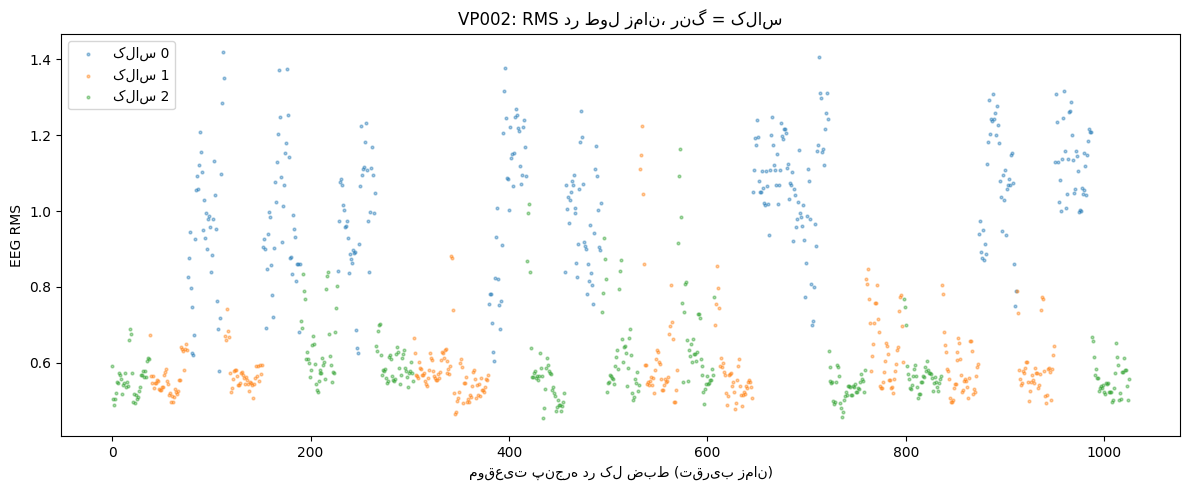

In [2]:
#Diagnostic check session order confound · PY
"""
تست قطعی: آیا تفاوت RMS بین کلاس‌ها واقعاً «بار شناختی» است یا «اثر ترتیب زمانی ضبط»؟

منطق: اگر RMS با موقعیت زمانی پنجره در کل ضبط (نه با کلاس) همبستگی قوی داشته باشد،
یعنی این یک drift است، نه سیگنال شناختی واقعی.
"""
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

subject = "VP002"
base = rf"E:\kntu\Thesis\codes\Results\MULTIMODAL_PREPROCESSED\{subject}"

eeg = np.load(f"{base}\\{subject}_eeg_windows.npy")      # (N, 16, 16, 600)
labels = np.load(f"{base}\\{subject}_labels.npy")        # (N,)

eeg_rms = np.sqrt(np.mean(eeg**2, axis=(1, 2, 3)))
window_index = np.arange(len(labels))  # موقعیت پنجره در ترتیب استخراج = تقریب موقعیت زمانی در کل ضبط

# ===== چک ۱: همبستگی RMS با موقعیت زمانی (صرف‌نظر از کلاس) =====
corr, p_corr = stats.pearsonr(window_index, eeg_rms)
print(f"همبستگی RMS با موقعیت زمانی پنجره (کل ضبط): r={corr:.3f}, p={p_corr:.4g}")
print("(اگر |r| بزرگ بود، یعنی drift زمانی داریم -- نه صرفاً تفاوت کلاس)")

# ===== چک ۲: توزیع زمانی هر کلاس -- آیا کلاس‌ها در بخش‌های جدا از ضبط اتفاق افتاده‌اند؟ =====
print("\nموقعیت زمانی (شاخص پنجره) هر کلاس در کل ضبط:")
for cls in [0, 1, 2]:
    idx = window_index[labels == cls]
    print(f"  کلاس {cls}: از پنجرهٔ {idx.min()} تا {idx.max()}  (میانگین موقعیت={idx.mean():.0f})")

# اگر بازه‌های بالا کاملاً از هم جدا باشند (مثلاً کلاس 0: 0-300، کلاس 1: 300-650، کلاس 2: 650-1026)
# یعنی کلاس‌ها واقعاً در بلوک‌های زمانی مجزا ضبط شده‌اند -- این خودش تأیید نیمه‌قطعی confound است.

# ===== چک ۳: روند RMS در طول زمان، جدا برای هر کلاس =====
# اگر RMS حتی «درون» یک کلاس با گذشت زمان (شماره‌ی تکرار trial) به‌طور یکنواخت کم/زیاد شود،
# نشانه‌ی قوی drift است.
plt.figure(figsize=(12, 5))
colors = {0: 'tab:blue', 1: 'tab:orange', 2: 'tab:green'}
for cls in [0, 1, 2]:
    idx = window_index[labels == cls]
    vals = eeg_rms[labels == cls]
    plt.scatter(idx, vals, s=4, alpha=0.4, color=colors[cls], label=f'کلاس {cls}')
plt.xlabel("موقعیت پنجره در کل ضبط (تقریب زمان)")
plt.ylabel("EEG RMS")
plt.title(f"{subject}: RMS در طول زمان، رنگ = کلاس")
plt.legend()
plt.tight_layout()
plt.savefig(f"{subject}_rms_vs_time_by_class.png", dpi=150)
print(f"\nنمودار ذخیره شد: {subject}_rms_vs_time_by_class.png")
print("این نمودار را حتماً نگاه کنید: اگر سه کلاس در سه بازهٔ افقی کاملاً جدا از هم")
print("(نه قاطی‌شده در طول محور x) دیده شدند، یعنی confound ترتیب ضبط تأیید می‌شود.")

In [3]:
#Diagnostic check multi subject · PY
"""
چک تکرارپذیری: آیا الگوی «RMS کلاس ۰ تقریباً دو برابر کلاس ۱/۲» در چند سوژهٔ دیگر هم دیده می‌شود؟
این نسخهٔ چندسوژه‌ای همان چک ANOVA قبلی است، فقط روی چند سوژه حلقه می‌زند و نتیجه را
در یک جدول خلاصه کنار هم می‌گذارد تا مقایسه راحت باشد.
"""
import numpy as np
from scipy import stats

# چند سوژهٔ متنوع (شامل چند سوژهٔ باکیفیت خوب و یکی دو تا با کانال bad بیشتر، برای تنوع)
SUBJECTS = ["VP001", "VP002", "VP003", "VP005", "VP008", "VP010", "VP015", "VP020"]

BASE_PATH = r"E:\kntu\Thesis\codes\Results\MULTIMODAL_PREPROCESSED"

results = []

for subject in SUBJECTS:
    base = fr"{BASE_PATH}\{subject}"
    try:
        eeg = np.load(fr"{base}\{subject}_eeg_windows.npy")      # (N, 16, 16, 600)
        nirs = np.load(fr"{base}\{subject}_fnirs_windows.npy")   # (N, 2, 100, 16, 16)
        labels = np.load(fr"{base}\{subject}_labels.npy")        # (N,)
    except FileNotFoundError as e:
        print(f"{subject}: فایل پیدا نشد -- رد شد ({e})")
        continue

    eeg_rms = np.sqrt(np.mean(eeg**2, axis=(1, 2, 3)))
    rms_by_class = [eeg_rms[labels == c] for c in [0, 1, 2]]

    means = [v.mean() for v in rms_by_class]
    f_stat, p_val = stats.f_oneway(*rms_by_class)

    # نسبت کلاس ۰ به میانگین کلاس‌های ۱ و ۲ -- عدد کلیدی برای مقایسهٔ بین سوژه‌ها
    ratio_0_to_12 = means[0] / np.mean(means[1:3])

    nirs_hbo_mean = nirs[:, 0, :, :, :].mean(axis=(1, 2, 3))
    hbo_by_class = [nirs_hbo_mean[labels == c] for c in [0, 1, 2]]
    f_stat_n, p_val_n = stats.f_oneway(*hbo_by_class)

    results.append({
        "subject": subject,
        "n": len(labels),
        "rms_0": means[0], "rms_1": means[1], "rms_2": means[2],
        "ratio_0_to_12": ratio_0_to_12,
        "F_eeg": f_stat, "p_eeg": p_val,
        "F_nirs": f_stat_n, "p_nirs": p_val_n,
    })

    print(f"{subject}: RMS0={means[0]:.4f}  RMS1={means[1]:.4f}  RMS2={means[2]:.4f}  "
          f"نسبت0/میانگین(1,2)={ratio_0_to_12:.3f}  F_EEG={f_stat:.1f} (p={p_val:.2e})  "
          f"F_fNIRS={f_stat_n:.1f} (p={p_val_n:.2e})")

print("\n" + "=" * 90)
print(f"{'سوژه':<8}{'RMS کلاس0':>12}{'RMS کلاس1':>12}{'RMS کلاس2':>12}{'نسبت 0/میانگین(1,2)':>22}")
for r in results:
    print(f"{r['subject']:<8}{r['rms_0']:>12.4f}{r['rms_1']:>12.4f}{r['rms_2']:>12.4f}{r['ratio_0_to_12']:>22.3f}")

ratios = [r["ratio_0_to_12"] for r in results]
print(f"\nمیانگین نسبت بین سوژه‌ها: {np.mean(ratios):.3f}   انحراف‌معیار: {np.std(ratios):.3f}")
print("(اگر این نسبت در همهٔ سوژه‌ها نزدیک به هم بود -> یک ویژگی سیستماتیک تکلیف است)")
print("(اگر خیلی پراکنده بود -> احتمال آرتیفکت فردی/رفتاری بیشتر می‌شود)")

n_significant_eeg = sum(1 for r in results if r["p_eeg"] < 0.05)
n_significant_nirs = sum(1 for r in results if r["p_nirs"] < 0.05)
print(f"\nتعداد سوژه با EEG معنادار (p<0.05): {n_significant_eeg}/{len(results)}")
print(f"تعداد سوژه با fNIRS معنادار (p<0.05): {n_significant_nirs}/{len(results)}")

VP001: RMS0=0.7573  RMS1=0.7347  RMS2=0.7491  نسبت0/میانگین(1,2)=1.021  F_EEG=1.5 (p=2.33e-01)  F_fNIRS=37.1 (p=2.69e-16)
VP002: RMS0=1.0322  RMS1=0.5919  RMS2=0.5940  نسبت0/میانگین(1,2)=1.741  F_EEG=1416.1 (p=0.00e+00)  F_fNIRS=32.8 (p=1.51e-14)
VP003: RMS0=0.7982  RMS1=0.7065  RMS2=0.7084  نسبت0/میانگین(1,2)=1.128  F_EEG=308.9 (p=0.00e+00)  F_fNIRS=34.7 (p=2.53e-15)
VP005: RMS0=0.7058  RMS1=0.6767  RMS2=0.6730  نسبت0/میانگین(1,2)=1.046  F_EEG=9.4 (p=9.43e-05)  F_fNIRS=6.7 (p=1.32e-03)
VP008: RMS0=0.7565  RMS1=0.7195  RMS2=0.7109  نسبت0/میانگین(1,2)=1.058  F_EEG=42.3 (p=2.24e-18)  F_fNIRS=0.6 (p=5.34e-01)
VP010: RMS0=0.7727  RMS1=0.6861  RMS2=0.6891  نسبت0/میانگین(1,2)=1.124  F_EEG=50.9 (p=8.81e-22)  F_fNIRS=6.9 (p=1.06e-03)
VP015: RMS0=0.7186  RMS1=0.6808  RMS2=0.6643  نسبت0/میانگین(1,2)=1.068  F_EEG=30.6 (p=1.30e-13)  F_fNIRS=36.9 (p=3.27e-16)
VP020: RMS0=0.7777  RMS1=0.7729  RMS2=0.7511  نسبت0/میانگین(1,2)=1.021  F_EEG=7.5 (p=5.70e-04)  F_fNIRS=8.1 (p=3.09e-04)

سوژه       RMS کلاس

In [4]:
#Diagnostic check eeg fnirs sync · PY
"""
چک تشخیصی: آیا مارکرهای trial که EEG و fNIRS مستقل از هم ثبت کرده‌اند، واقعاً روی هم منطبق‌اند؟

منطق: EEG و fNIRS دو دستگاه ضبط جداگانه‌اند، هرکدام مارکر trial خودشان را دارند
(EEG: کدهای 112/128/144 ,  fNIRS: کدهای 7/8/9). اگر این دو دستگاه یک origin زمانی
مشترک نداشته باشند (یا کمی drift کرده باشند)، پایپلاین فعلی -- که فقط از مارکر EEG
برای ایندکس‌گذاری داخل سیگنال fNIRS استفاده می‌کند -- می‌تواند بی‌صدا پنجره‌های fNIRS
را به لحظه‌ی اشتباهی بچسباند.

این اسکریپت مستقیماً دو مارکر را (زمان + کلاس) کنار هم می‌گذارد و می‌سنجد.
"""
import os
import numpy as np
import scipy.io as sio

BASE_DATASET_PATH = r"E:\kntu\Thesis\codes\DATA"
SUBJECTS = ["VP001", "VP002", "VP003", "VP005", "VP008"]

EEG_TRIAL_LABEL_MAP = {112: 0, 128: 1, 144: 2}
FNIRS_TRIAL_LABEL_MAP = {7: 0, 8: 1, 9: 2}


def load_trial_markers(mrk_path, label_map):
    """برمی‌گرداند: آرایه‌ی زمان (ثانیه) و آرایه‌ی کلاس (0/1/2)، فقط برای رویدادهای trial-level."""
    mat = sio.loadmat(mrk_path, struct_as_record=False, squeeze_me=True)
    key = [k for k in mat.keys() if not k.startswith('__')][0]
    mrk = mat[key]

    time_ms = np.asarray(mrk.time).flatten().astype(float)  # بر اساس ساختار فایل، زمان به میلی‌ثانیه است
    desc = np.asarray(mrk.event.desc).flatten().astype(int)

    mask = np.isin(desc, list(label_map.keys()))
    times_sec = time_ms[mask] / 1000.0
    classes = np.array([label_map[c] for c in desc[mask]])

    # مرتب‌سازی بر اساس زمان (باید از قبل مرتب باشد، ولی برای اطمینان)
    order = np.argsort(times_sec)
    return times_sec[order], classes[order]


print(f"{'سوژه':<8}{'#trial EEG':<12}{'#trial fNIRS':<14}{'ترتیب کلاس یکسان؟':<20}{'میانگین Δt (s)':<18}{'std Δt (s)':<14}{'max|Δt| (s)':<14}")

for subject in SUBJECTS:
    eeg_mrk_path = os.path.join(BASE_DATASET_PATH, f"{subject}-EEG", "mrk_nback.mat")
    fnirs_mrk_path = os.path.join(BASE_DATASET_PATH, f"{subject}-NIRS", "mrk_nback.mat")

    try:
        t_eeg, cls_eeg = load_trial_markers(eeg_mrk_path, EEG_TRIAL_LABEL_MAP)
        t_fnirs, cls_fnirs = load_trial_markers(fnirs_mrk_path, FNIRS_TRIAL_LABEL_MAP)
    except Exception as e:
        print(f"{subject}: خطا در بارگذاری -- {e}")
        continue

    n_eeg, n_fnirs = len(t_eeg), len(t_fnirs)
    n_common = min(n_eeg, n_fnirs)

    same_order = np.array_equal(cls_eeg[:n_common], cls_fnirs[:n_common])

    # فرض: trial شماره i در هر دو جریان مستقل، به همان رویداد فیزیکی واقعی اشاره دارد.
    # (زمان مطلق EEG) و (زمان مطلق fNIRS) باید تقریباً یکسان باشند اگر origin مشترک باشد.
    delta_t = t_fnirs[:n_common] - t_eeg[:n_common]

    print(f"{subject:<8}{n_eeg:<12}{n_fnirs:<14}{str(same_order):<20}"
          f"{delta_t.mean():<18.3f}{delta_t.std():<14.3f}{np.max(np.abs(delta_t)):<14.3f}")

    if not same_order:
        mismatch_idx = np.where(cls_eeg[:n_common] != cls_fnirs[:n_common])[0]
        print(f"    !! ترتیب کلاس‌ها متفاوت است در trial های: {mismatch_idx[:10]} ...")

print("\n" + "=" * 90)
print("تفسیر:")
print("- اگر 'ترتیب کلاس یکسان؟' False بود: یا مارکرها اشتباه فیلتر شده‌اند یا trial ها اصلاً")
print("  با هم متناظر نیستند -- این خودش یک باگ جدی است که باید جدا بررسی شود.")
print("- اگر میانگین Δt نزدیک صفر و std خیلی کوچک بود (مثلاً <0.5s): دو دستگاه هم‌زمان‌اند,")
print("  فرض 'origin زمانی مشترک' که پایپلاین بر پایه‌اش ساخته شده درست است.")
print("- اگر میانگین Δt یک عدد ثابت و غیرصفر بود (مثلاً همیشه +3.2s): یک OFFSET ثابت")
print("  بین دو دستگاه هست -- یعنی همه‌ی پنجره‌های fNIRS شما سیستماتیک جابه‌جا بوده‌اند!")
print("- اگر Δt با گذشت زمان (trial های بعدی) بزرگ‌تر می‌شد: drift ساعت بین دو دستگاه داریم.")

سوژه    #trial EEG  #trial fNIRS  ترتیب کلاس یکسان؟   میانگین Δt (s)    std Δt (s)    max|Δt| (s)   
VP001   27          27            True                63.121            38.162        110.114       
VP002   27          27            True                63.739            40.119        114.182       
VP003   27          27            True                67.572            40.274        116.478       
VP005   27          27            True                62.017            38.199        107.884       
VP008   27          27            True                61.091            39.012        108.919       

تفسیر:
- اگر 'ترتیب کلاس یکسان؟' False بود: یا مارکرها اشتباه فیلتر شده‌اند یا trial ها اصلاً
  با هم متناظر نیستند -- این خودش یک باگ جدی است که باید جدا بررسی شود.
- اگر میانگین Δt نزدیک صفر و std خیلی کوچک بود (مثلاً <0.5s): دو دستگاه هم‌زمان‌اند,
  فرض 'origin زمانی مشترک' که پایپلاین بر پایه‌اش ساخته شده درست است.
- اگر میانگین Δt یک عدد ثابت و غیرصفر بود (مثلاً همیشه +3.2s): یک OFFSET

In [5]:
#Diagnostic check trial shift · PY
"""
تست قطعی: آیا مارکرهای EEG و fNIRS با یک جابه‌جایی ایندکس (shift) واقعاً روی هم منطبق می‌شوند؟

اگر با shift=+1 یا shift=-1، میانگین/std دلتا به‌شدت کوچک شد (نزدیک صفر)،
یعنی مشکل واقعی یک "جابه‌جایی ایندکس" است، نه افست زمانی بین دو دستگاه.
"""
import os
import numpy as np
import scipy.io as sio

BASE_DATASET_PATH = r"E:\kntu\Thesis\codes\DATA"
SUBJECTS = ["VP001", "VP002", "VP003", "VP005", "VP008"]

EEG_TRIAL_LABEL_MAP = {112: 0, 128: 1, 144: 2}
FNIRS_TRIAL_LABEL_MAP = {7: 0, 8: 1, 9: 2}


def load_trial_markers(mrk_path, label_map):
    mat = sio.loadmat(mrk_path, struct_as_record=False, squeeze_me=True)
    key = [k for k in mat.keys() if not k.startswith('__')][0]
    mrk = mat[key]
    time_ms = np.asarray(mrk.time).flatten().astype(float)
    desc = np.asarray(mrk.event.desc).flatten().astype(int)
    mask = np.isin(desc, list(label_map.keys()))
    times_sec = time_ms[mask] / 1000.0
    classes = np.array([label_map[c] for c in desc[mask]])
    order = np.argsort(times_sec)
    return times_sec[order], classes[order]


print(f"{'سوژه':<8}{'shift':<8}{'میانگین Δt':<14}{'std Δt':<12}{'max|Δt|':<12}{'ترتیب کلاس یکسان؟':<18}")

for subject in SUBJECTS:
    eeg_mrk_path = os.path.join(BASE_DATASET_PATH, f"{subject}-EEG", "mrk_nback.mat")
    fnirs_mrk_path = os.path.join(BASE_DATASET_PATH, f"{subject}-NIRS", "mrk_nback.mat")

    try:
        t_eeg, cls_eeg = load_trial_markers(eeg_mrk_path, EEG_TRIAL_LABEL_MAP)
        t_fnirs, cls_fnirs = load_trial_markers(fnirs_mrk_path, FNIRS_TRIAL_LABEL_MAP)
    except Exception as e:
        print(f"{subject}: خطا -- {e}")
        continue

    # اول: چاپ خام تک‌تک دلتاها برای shift=0 تا الگو با چشم هم دیده شود
    n_common0 = min(len(t_eeg), len(t_fnirs))
    raw_delta = t_fnirs[:n_common0] - t_eeg[:n_common0]
    print(f"\n{subject} -- دلتای خام هر trial (shift=0):")
    print("  " + ", ".join(f"{d:.1f}" for d in raw_delta))

    best_shift, best_std = None, np.inf
    for shift in range(-3, 4):
        if shift >= 0:
            a, b = t_eeg[:len(t_eeg) - shift] if shift > 0 else t_eeg, t_fnirs[shift:]
            ca, cb = cls_eeg[:len(cls_eeg) - shift] if shift > 0 else cls_eeg, cls_fnirs[shift:]
        else:
            a, b = t_eeg[-shift:], t_fnirs[:len(t_fnirs) + shift]
            ca, cb = cls_eeg[-shift:], cls_fnirs[:len(cls_fnirs) + shift]

        n_common = min(len(a), len(b))
        if n_common < 5:
            continue
        delta = b[:n_common] - a[:n_common]
        same_order = np.array_equal(ca[:n_common], cb[:n_common])

        print(f"{subject:<8}{shift:<8}{delta.mean():<14.3f}{delta.std():<12.3f}"
              f"{np.max(np.abs(delta)):<12.3f}{str(same_order):<18}")

        if delta.std() < best_std:
            best_std = delta.std()
            best_shift = shift

    print(f"  --> بهترین shift برای {subject}: {best_shift} (کمترین std دلتا = {best_std:.3f}s)")

print("\n" + "=" * 90)
print("تفسیر:")
print("- اگر با یک shift خاص (مثلاً +1 یا -1)، std دلتا به زیر ۱ ثانیه افتاد: مشکل")
print("  دقیقاً 'جابه‌جایی ایندکس trial' بوده -- یعنی EEG_TRIAL_LABEL_MAP/FNIRS_TRIAL_LABEL_MAP")
print("  یا فیلتر کدها یک مارکر اضافی/کم در یکی از دو جریان باقی گذاشته.")
print("- اگر هیچ shift ای std را به‌طرز چشمگیری کم نکرد: مشکل جابه‌جایی ایندکس نیست،")
print("  و باید فرض 'دو دستگاه clock مشترک دارند' را جدی‌تر زیر سؤال ببریم.")

سوژه    shift   میانگین Δt    std Δt      max|Δt|     ترتیب کلاس یکسان؟ 

VP001 -- دلتای خام هر trial (shift=0):
  16.6, 16.6, 16.6, 16.6, 16.6, 16.6, 16.6, 16.6, 16.6, 62.8, 62.7, 62.7, 62.7, 62.7, 62.7, 62.7, 62.7, 62.7, 110.0, 110.1, 110.0, 110.0, 110.1, 110.1, 110.1, 110.0, 110.1
VP001   -3      -159.414      42.595      224.785     False             
VP001   -2      -84.863       41.590      155.148     False             
VP001   -1      -10.700       40.099      85.574      False             
VP001   0       63.121        38.162      110.114     True              
VP001   1       136.927       40.117      212.099     False             
VP001   2       211.075       41.623      281.699     False             
VP001   3       285.608       42.630      351.247     False             
  --> بهترین shift برای VP001: 0 (کمترین std دلتا = 38.162s)

VP002 -- دلتای خام هر trial (shift=0):
  16.0, 15.9, 16.0, 16.0, 16.0, 16.0, 16.0, 15.9, 15.9, 61.1, 61.1, 61.1, 61.1, 61.1, 61.1, 61.1, 61.1,